## Metrics

汇总常见2分类的指标，例如: AUC，ROC曲线，ACC, 敏感性， 特异性，精确度，召回率，PPV, NPV, F1

具体的介绍，可以参考一下：https://blog.csdn.net/sunflower_sara/article/details/81214897

In [1]:
import os
import pandas as pd
from datetime import datetime
from onekey_algo import get_param_in_cwd

os.makedirs('img', exist_ok=True)
os.makedirs('results', exist_ok=True)
group_info = pd.read_csv(get_param_in_cwd('label_file'))[['ID', 'group']]
group_info['ID'] = group_info['ID'].map(lambda x: str(x).replace('.nii.gz', ''))
display(group_info['group'].value_counts())
group_info

train    218
test1    174
test2     81
Name: group, dtype: int64

,ID,group
0,16,train
1,246,train
2,104,train
3,27,train
4,33,train
...,...,...
468,642,test2
469,643,test2
470,644,test2
471,645,test2


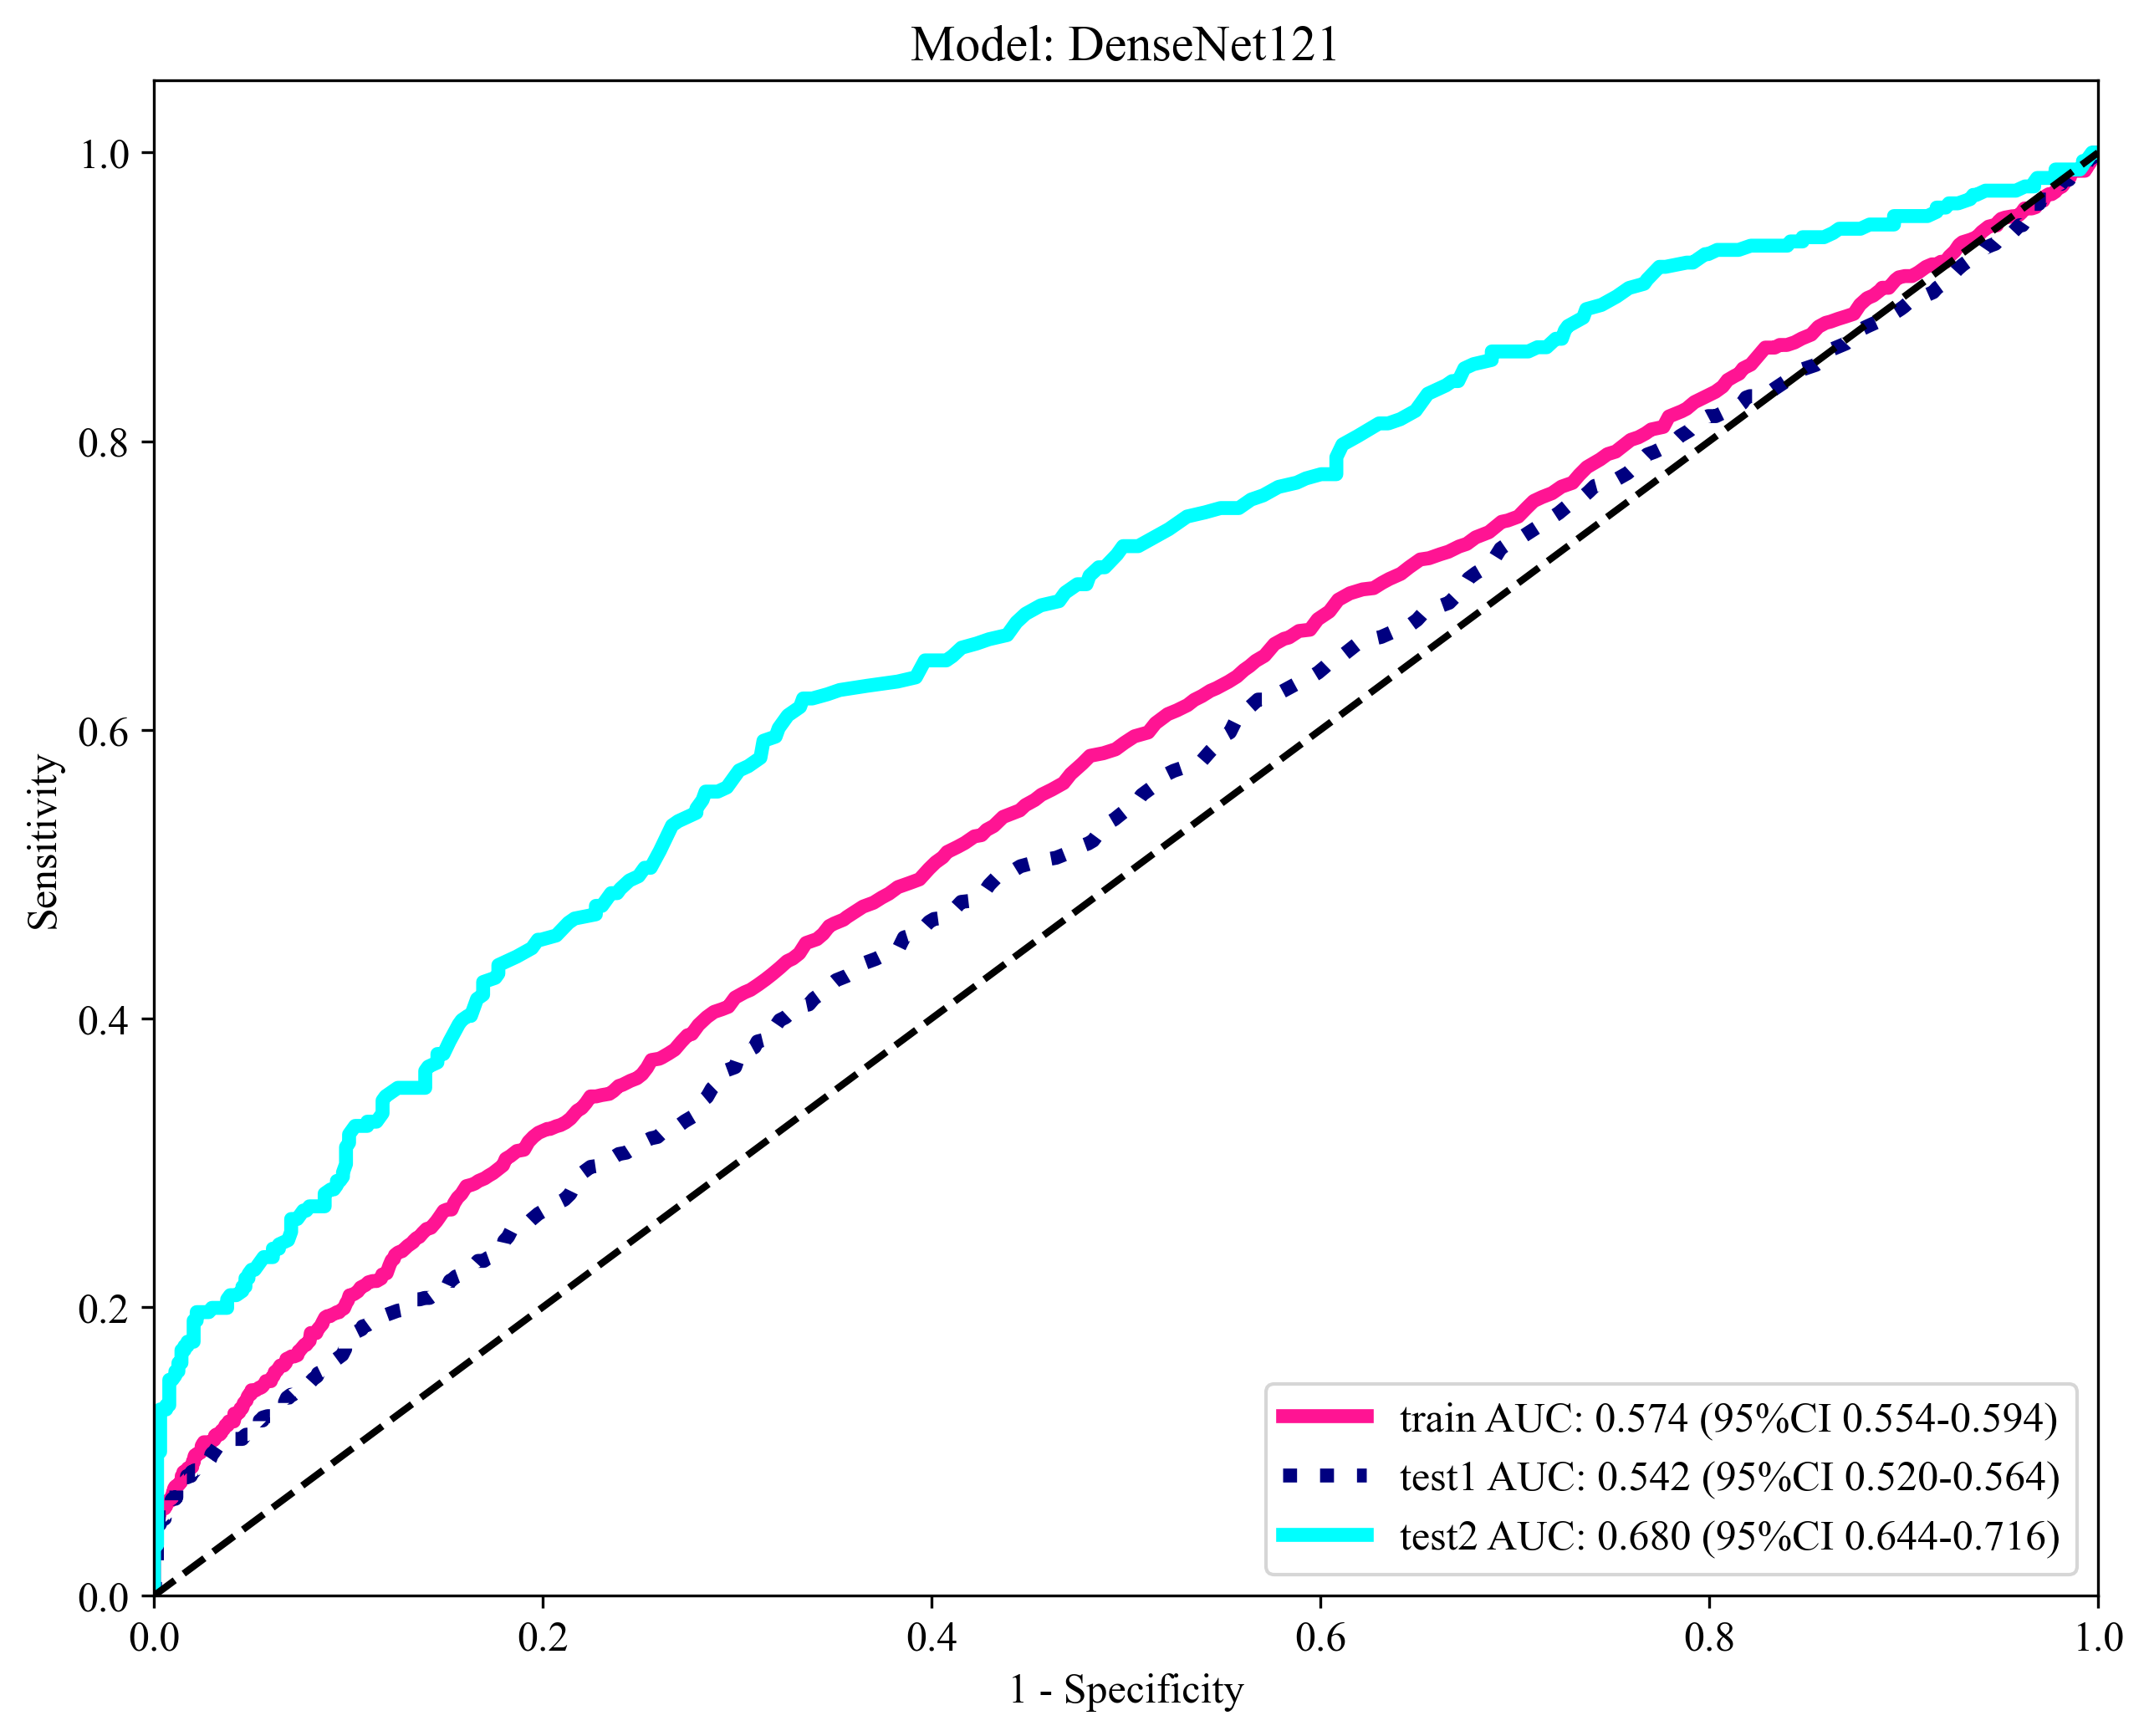

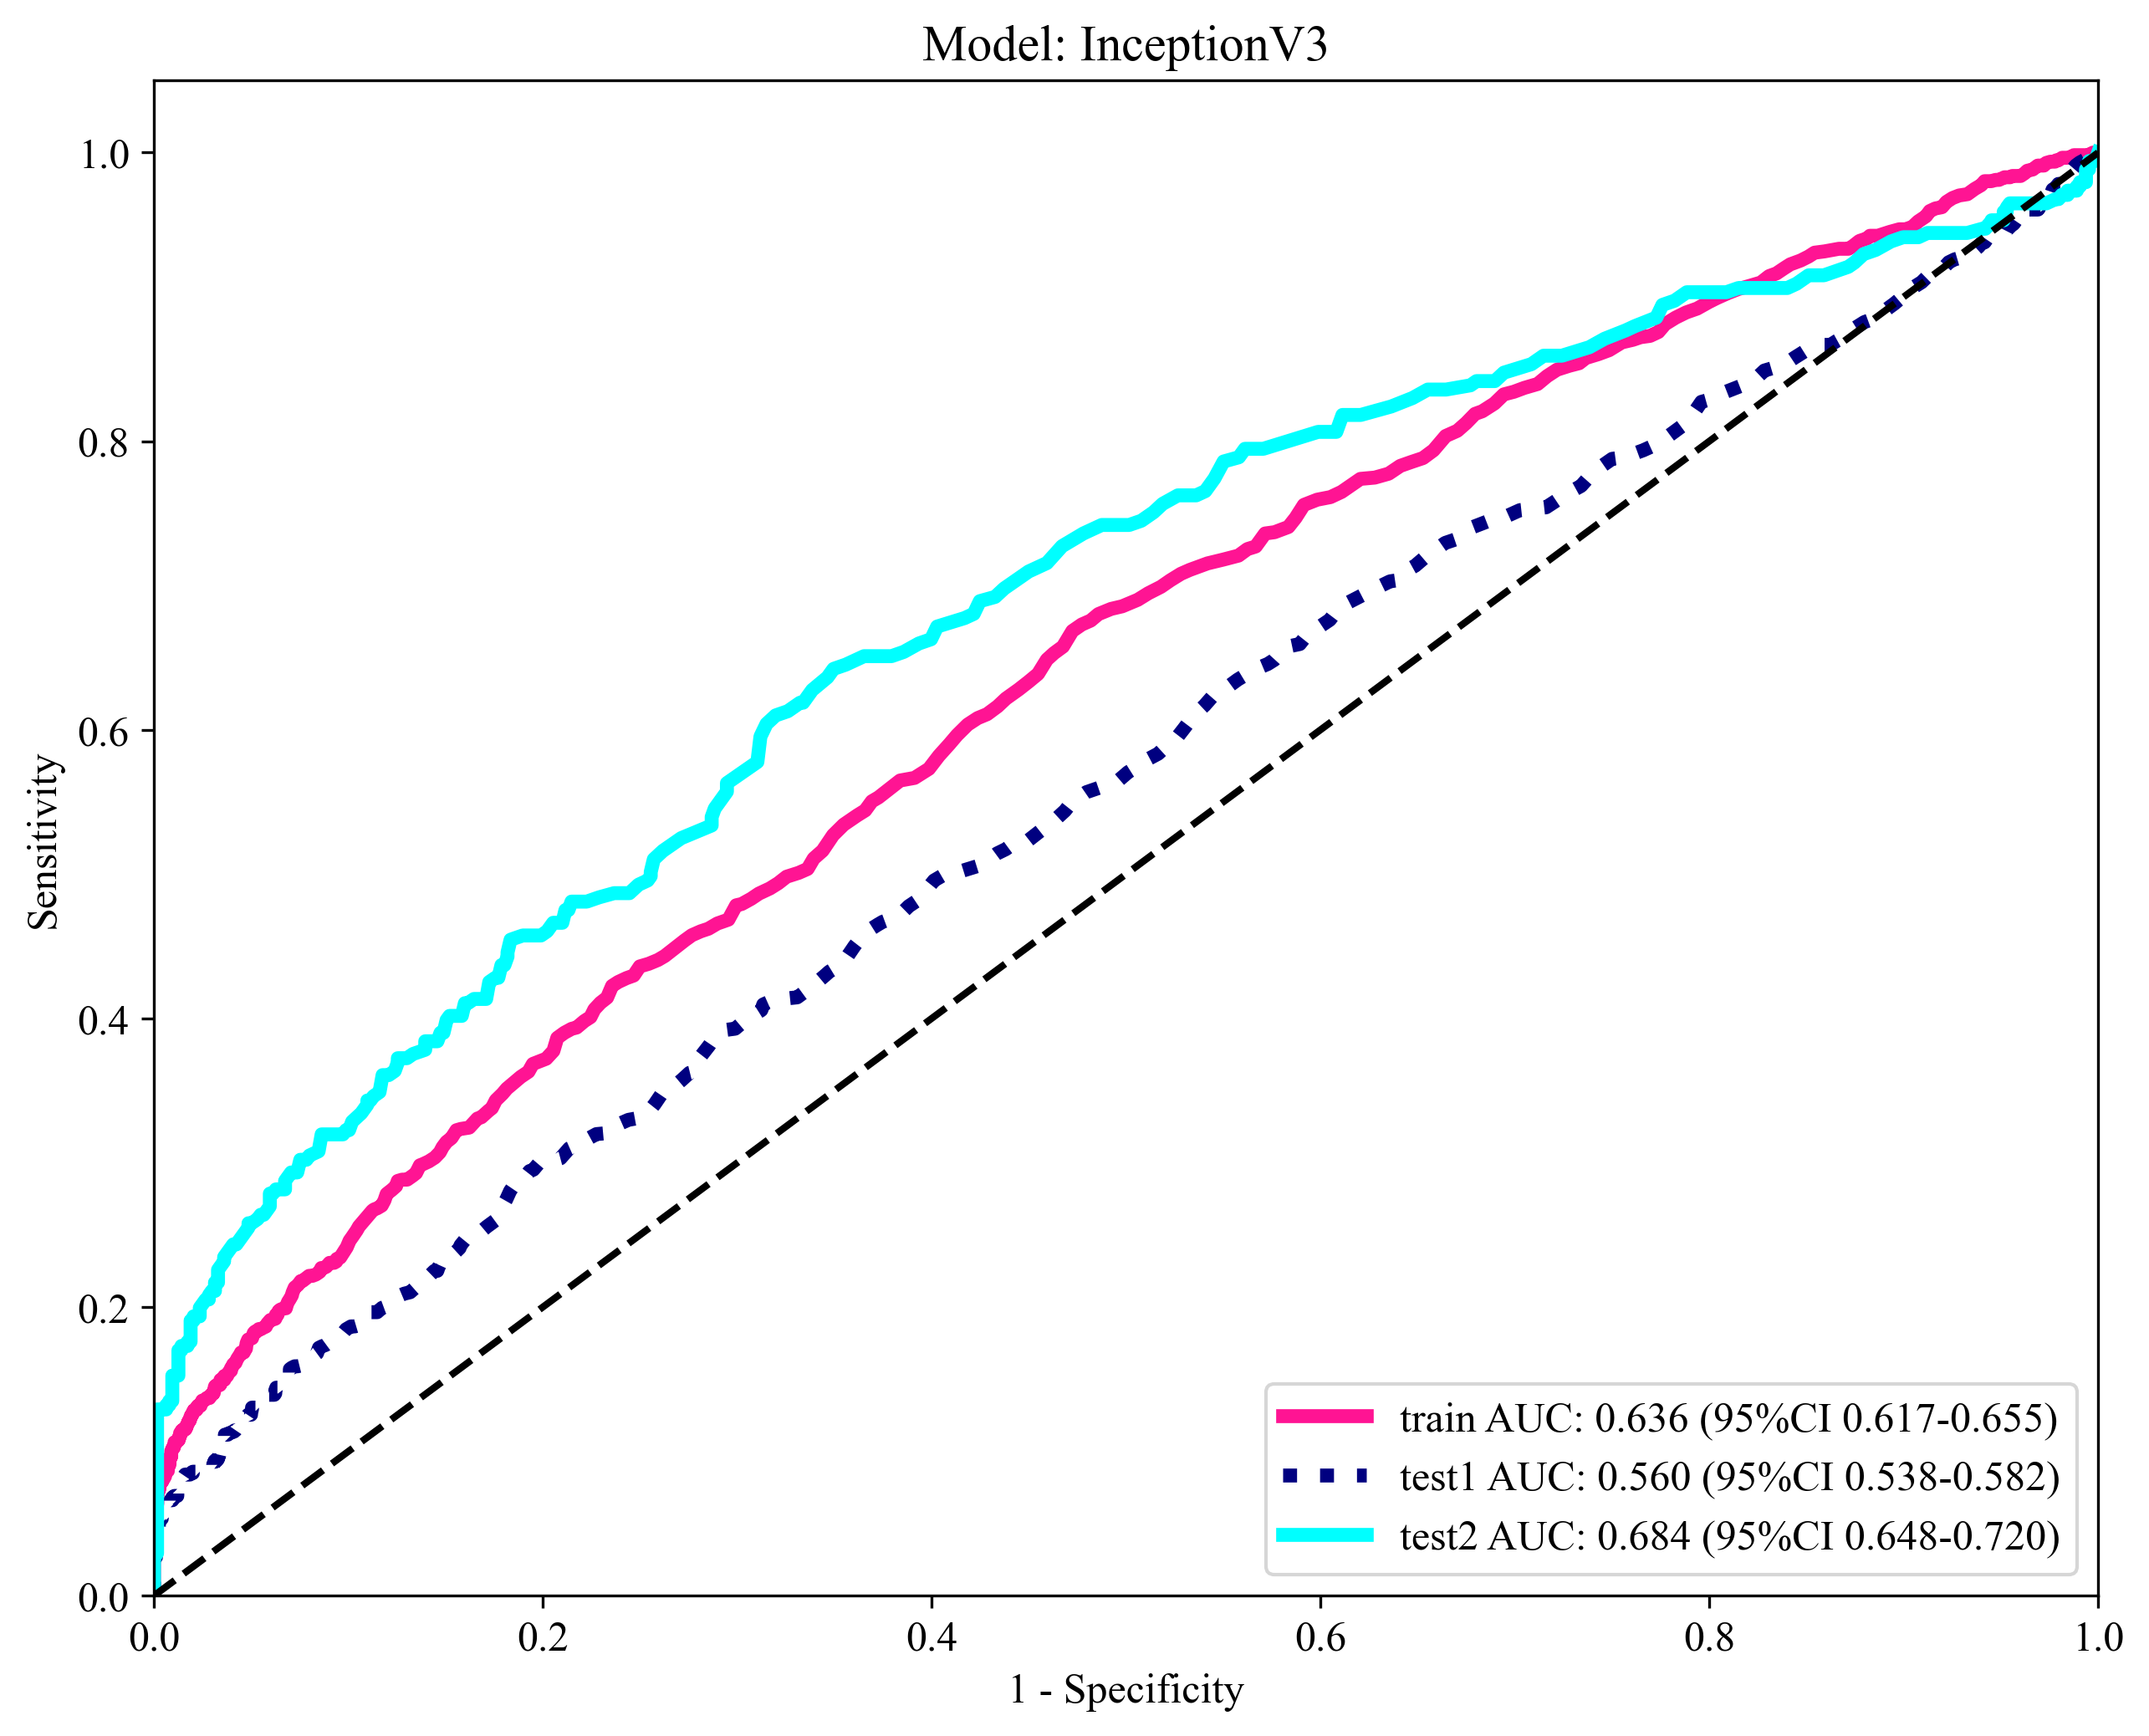

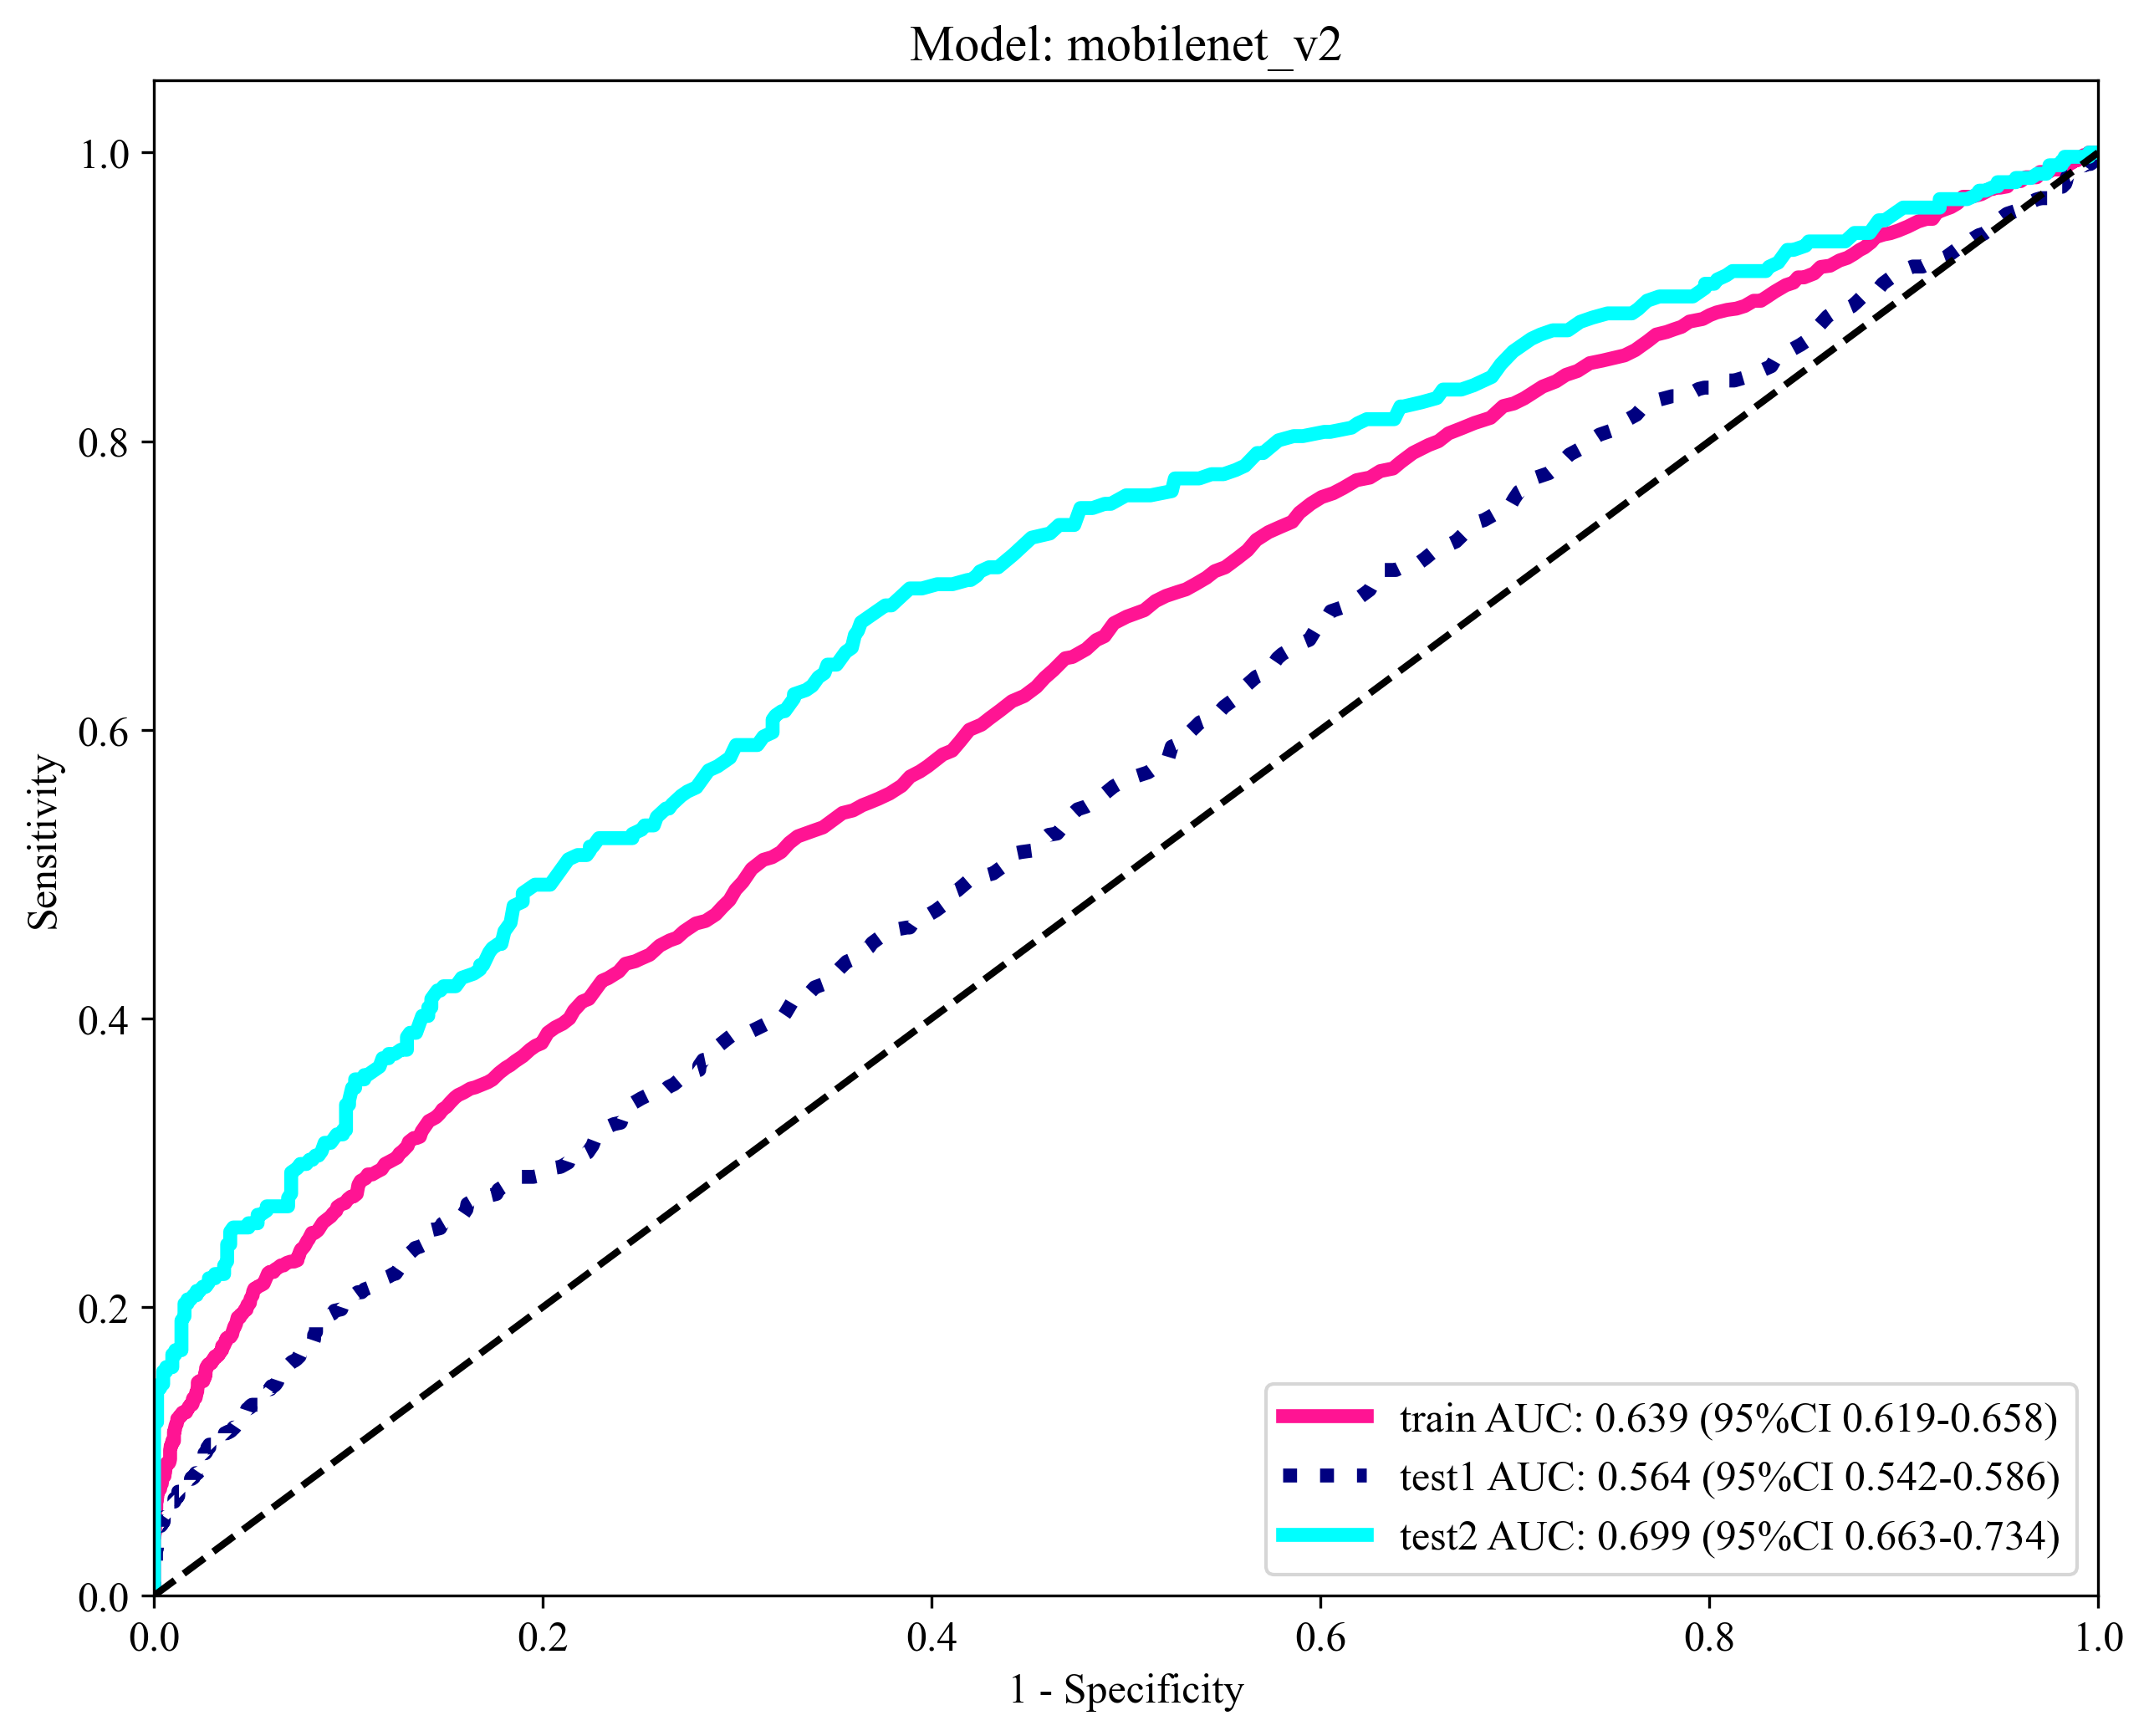

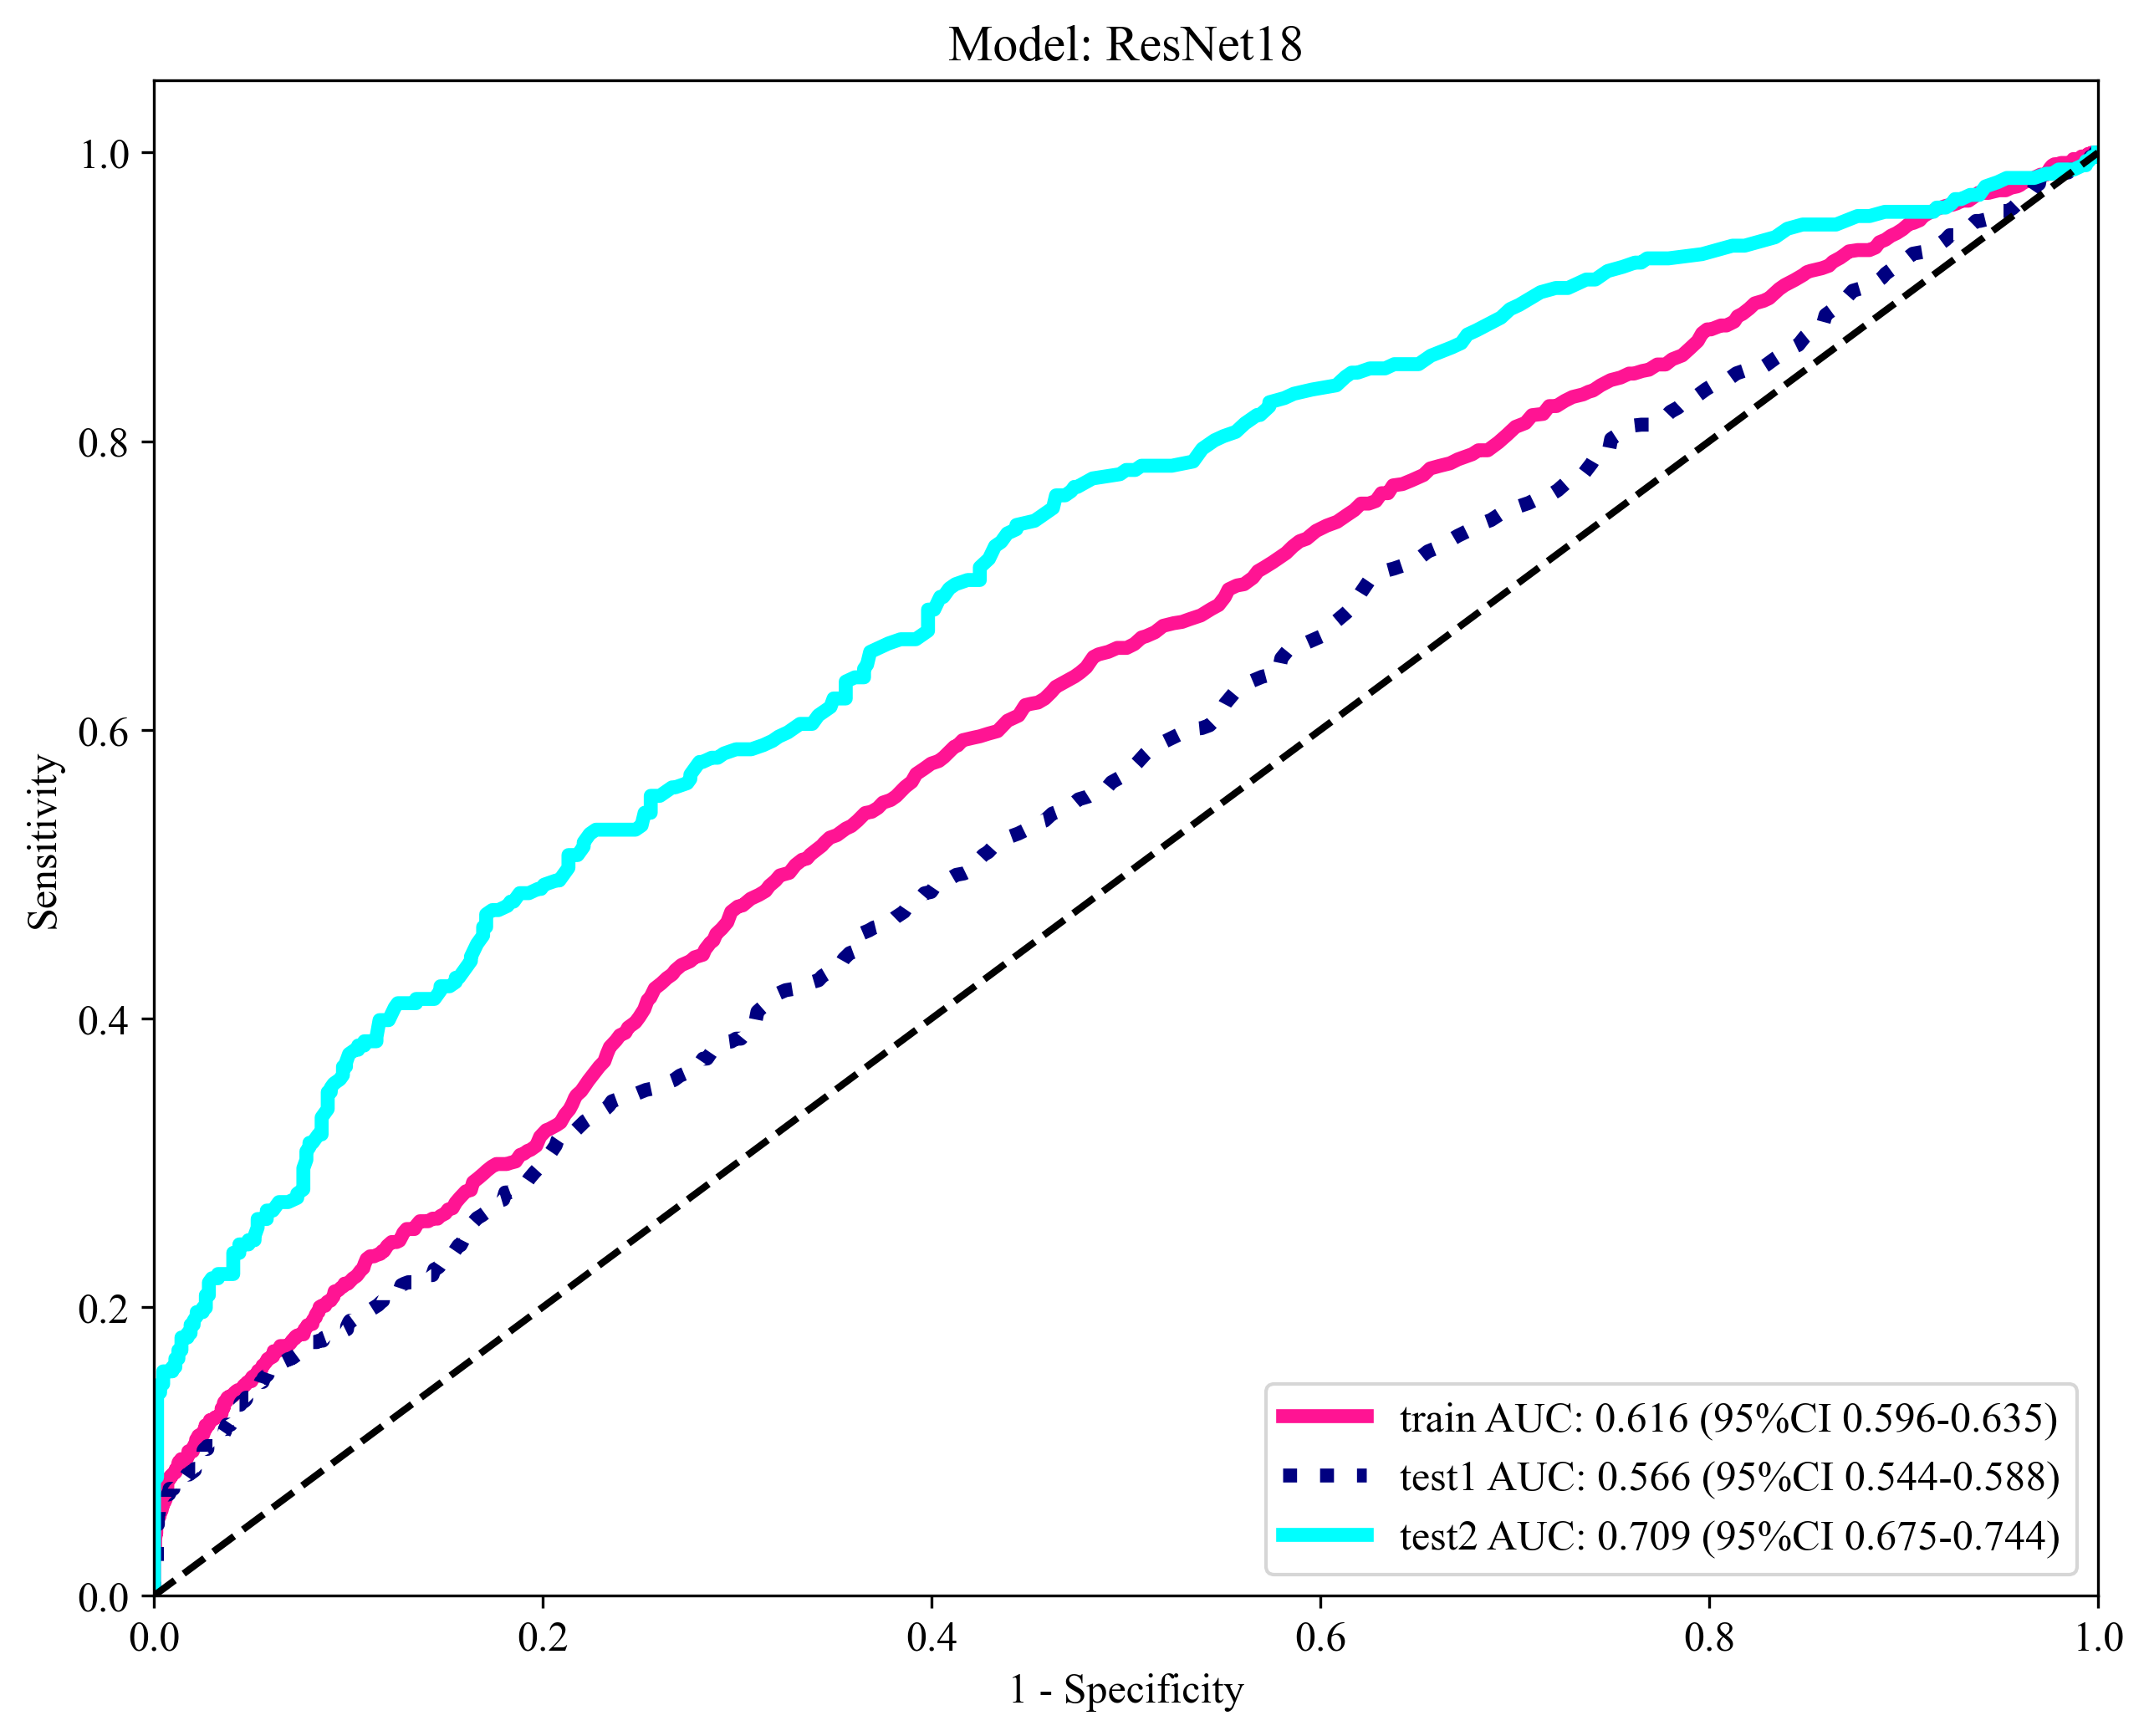

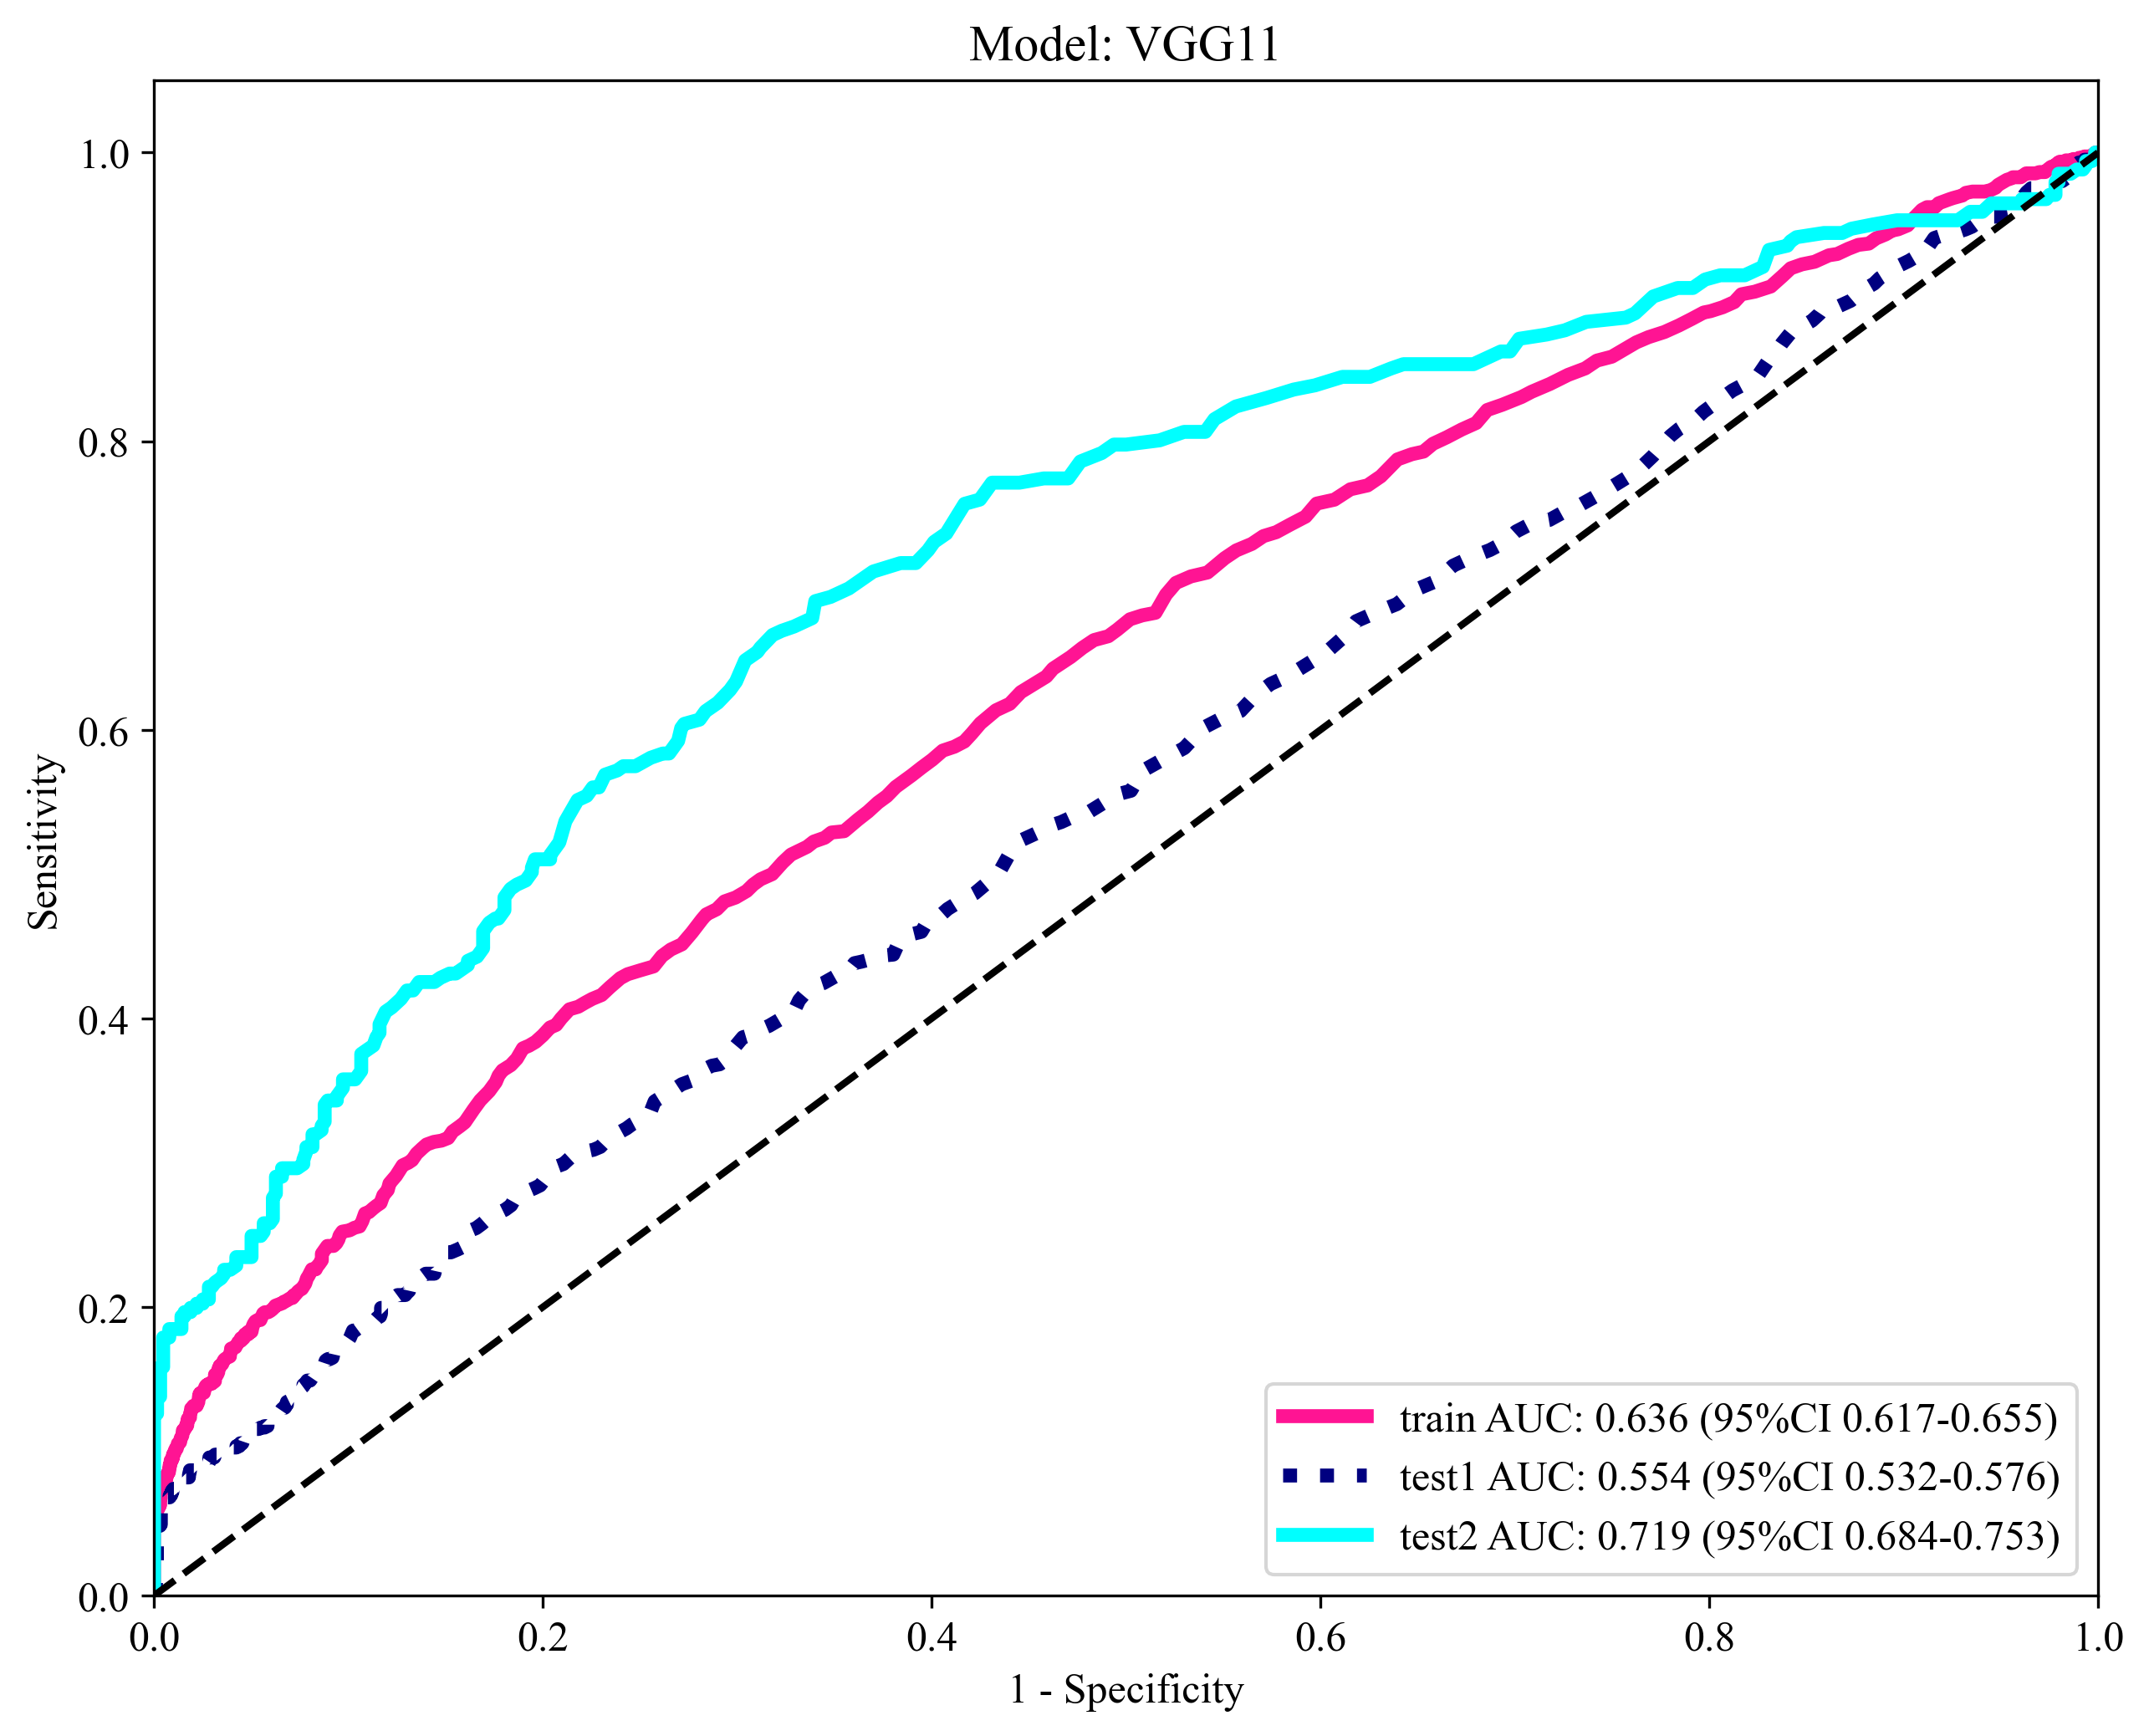

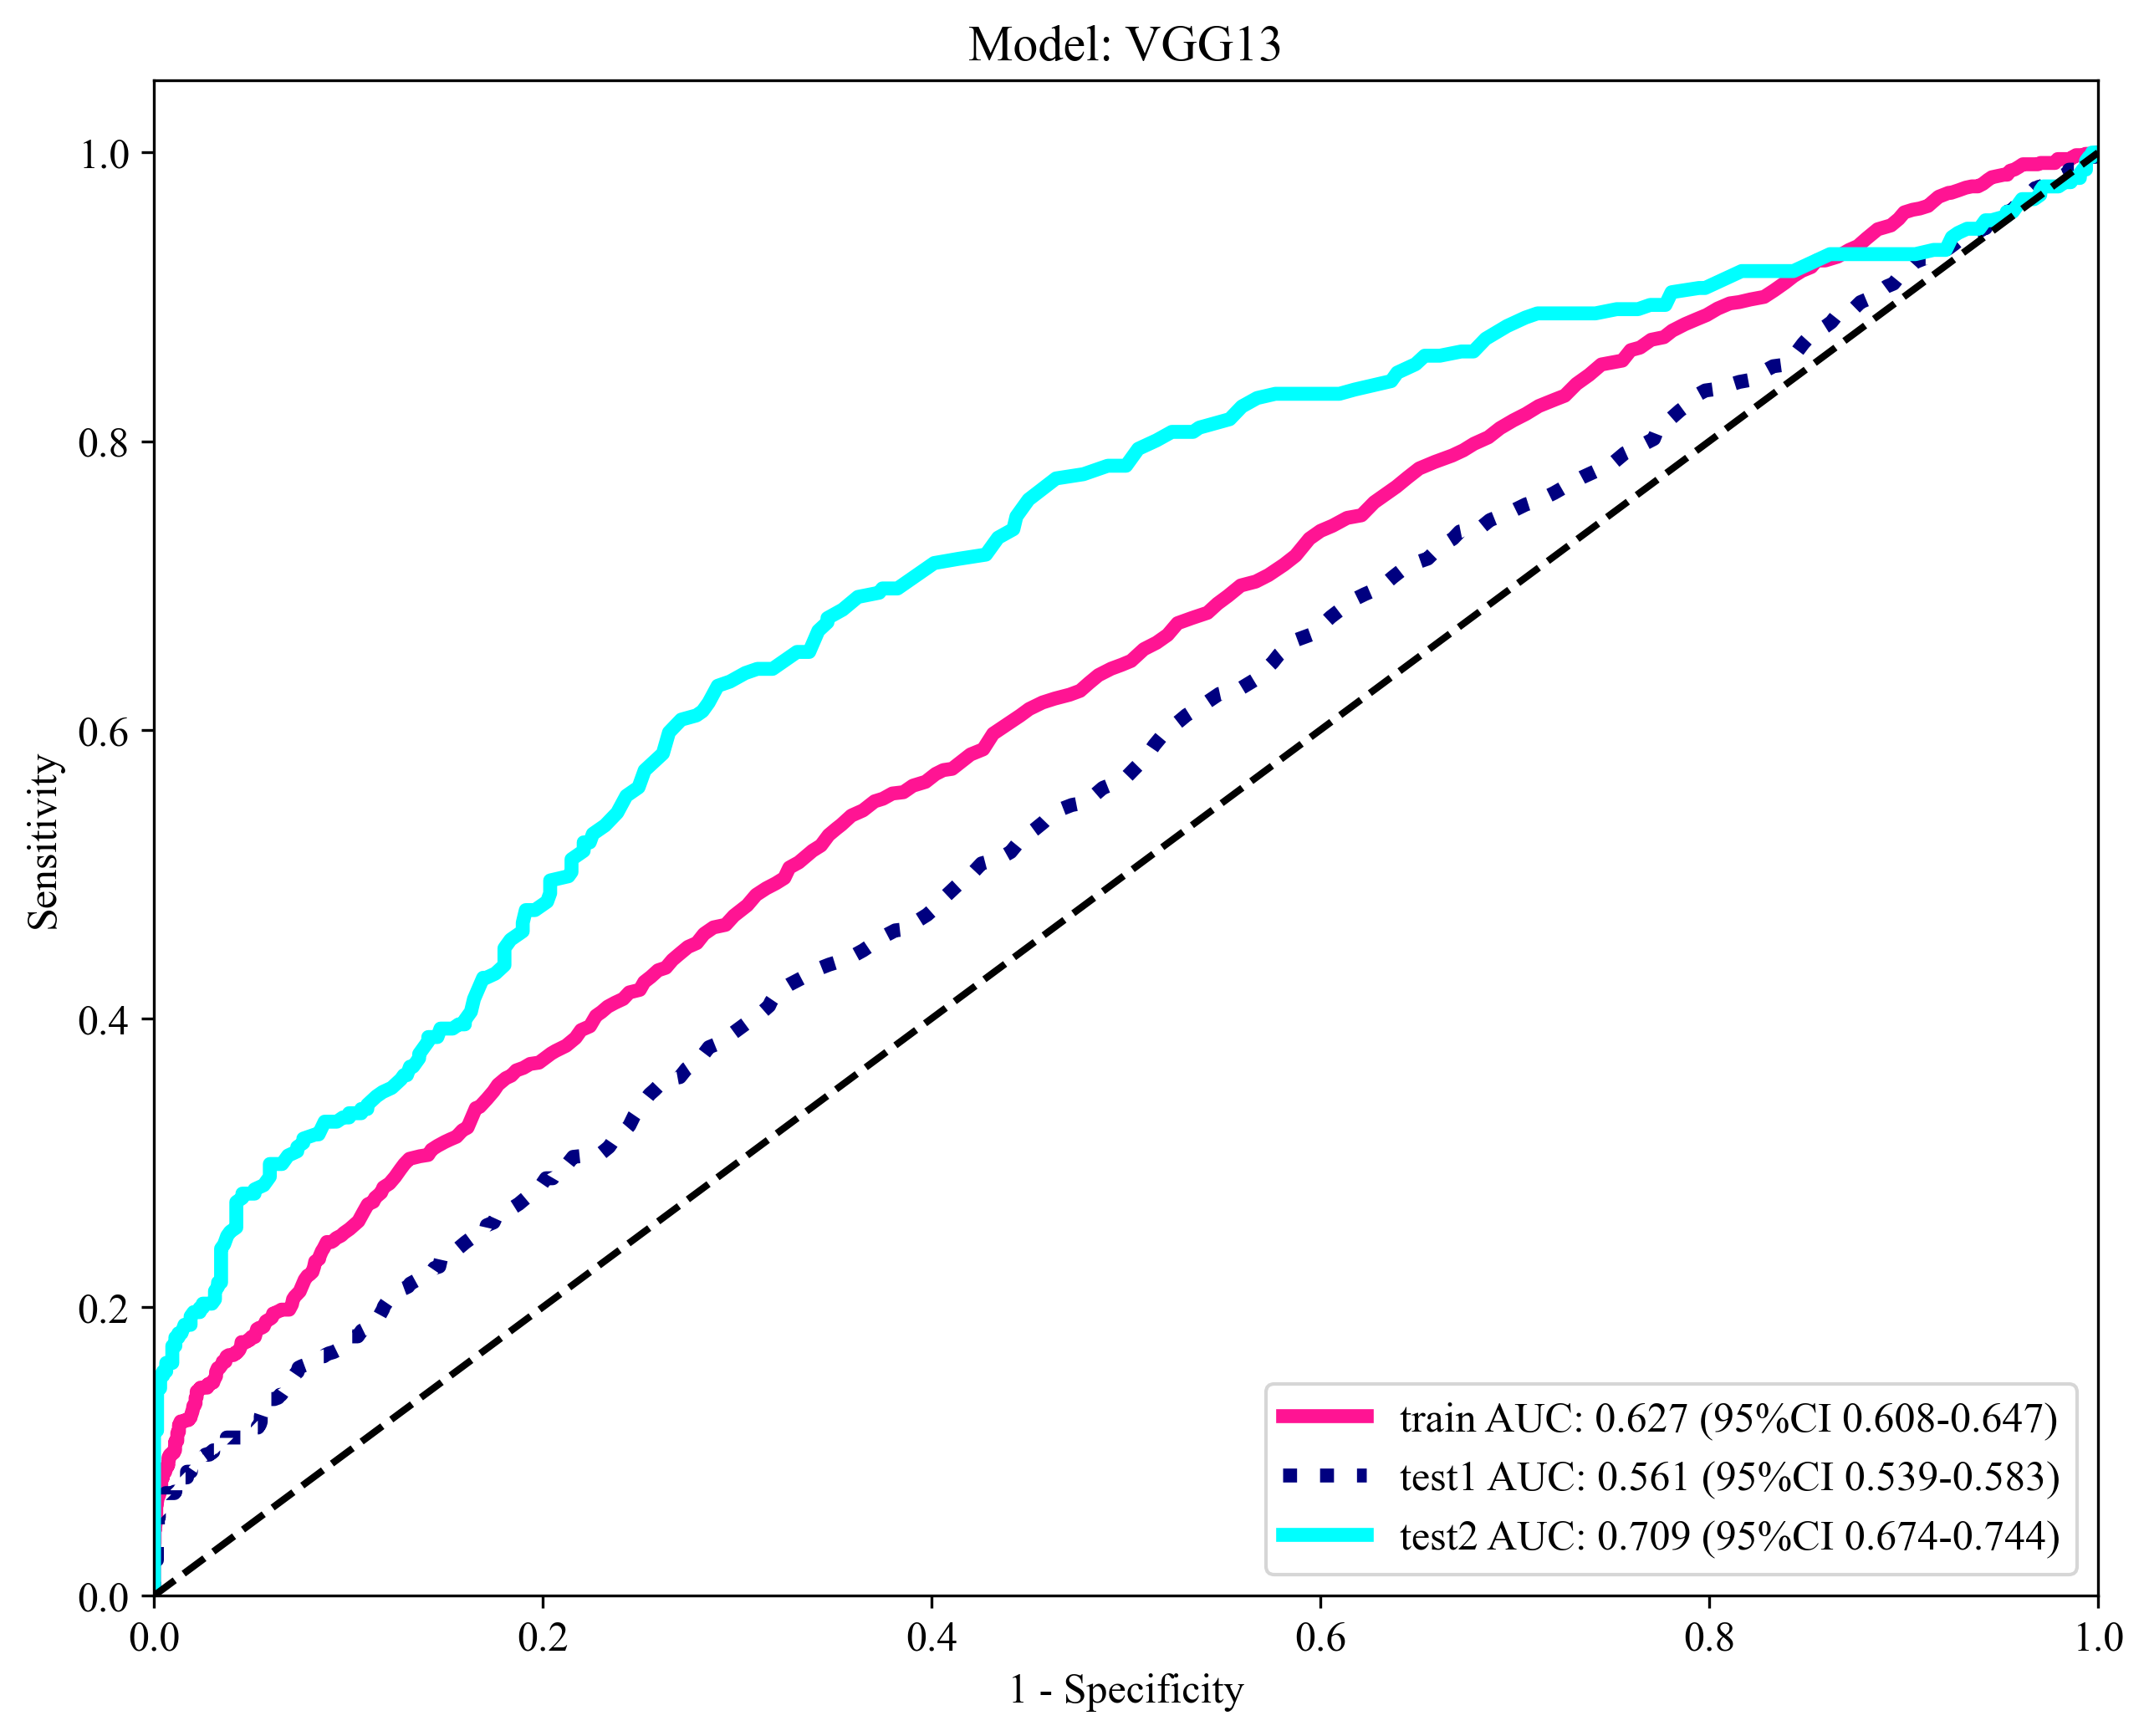

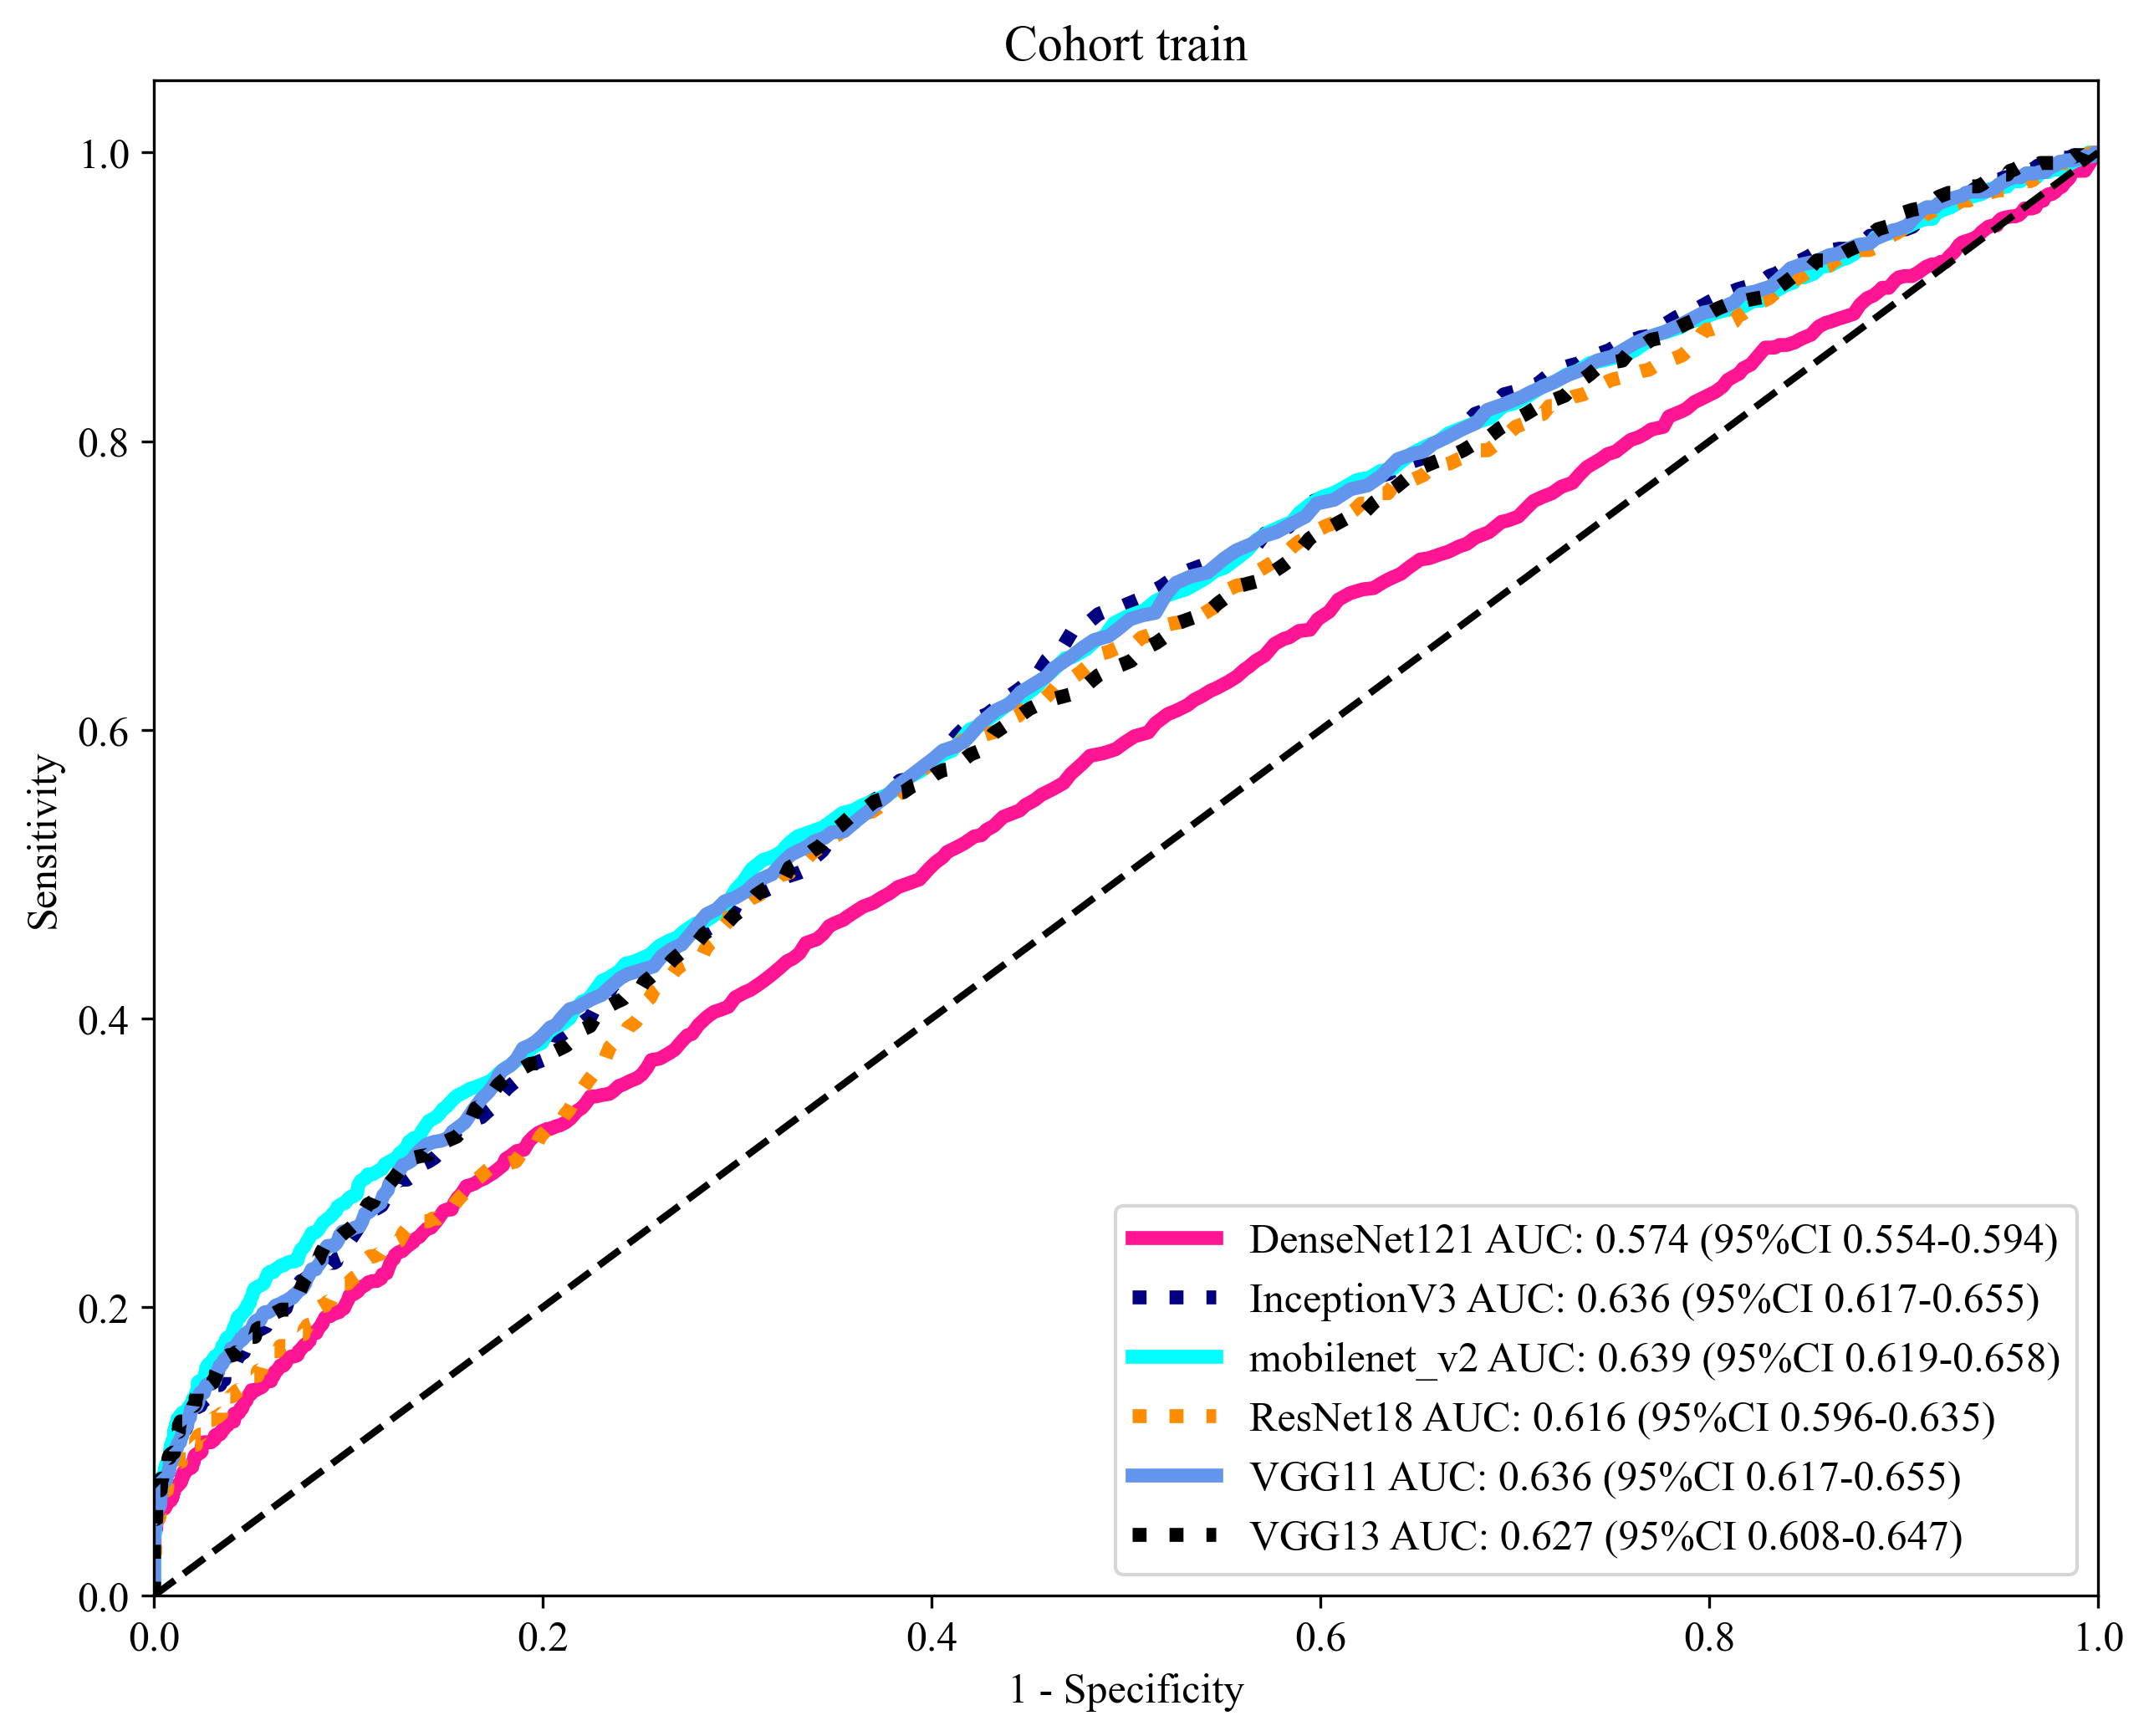

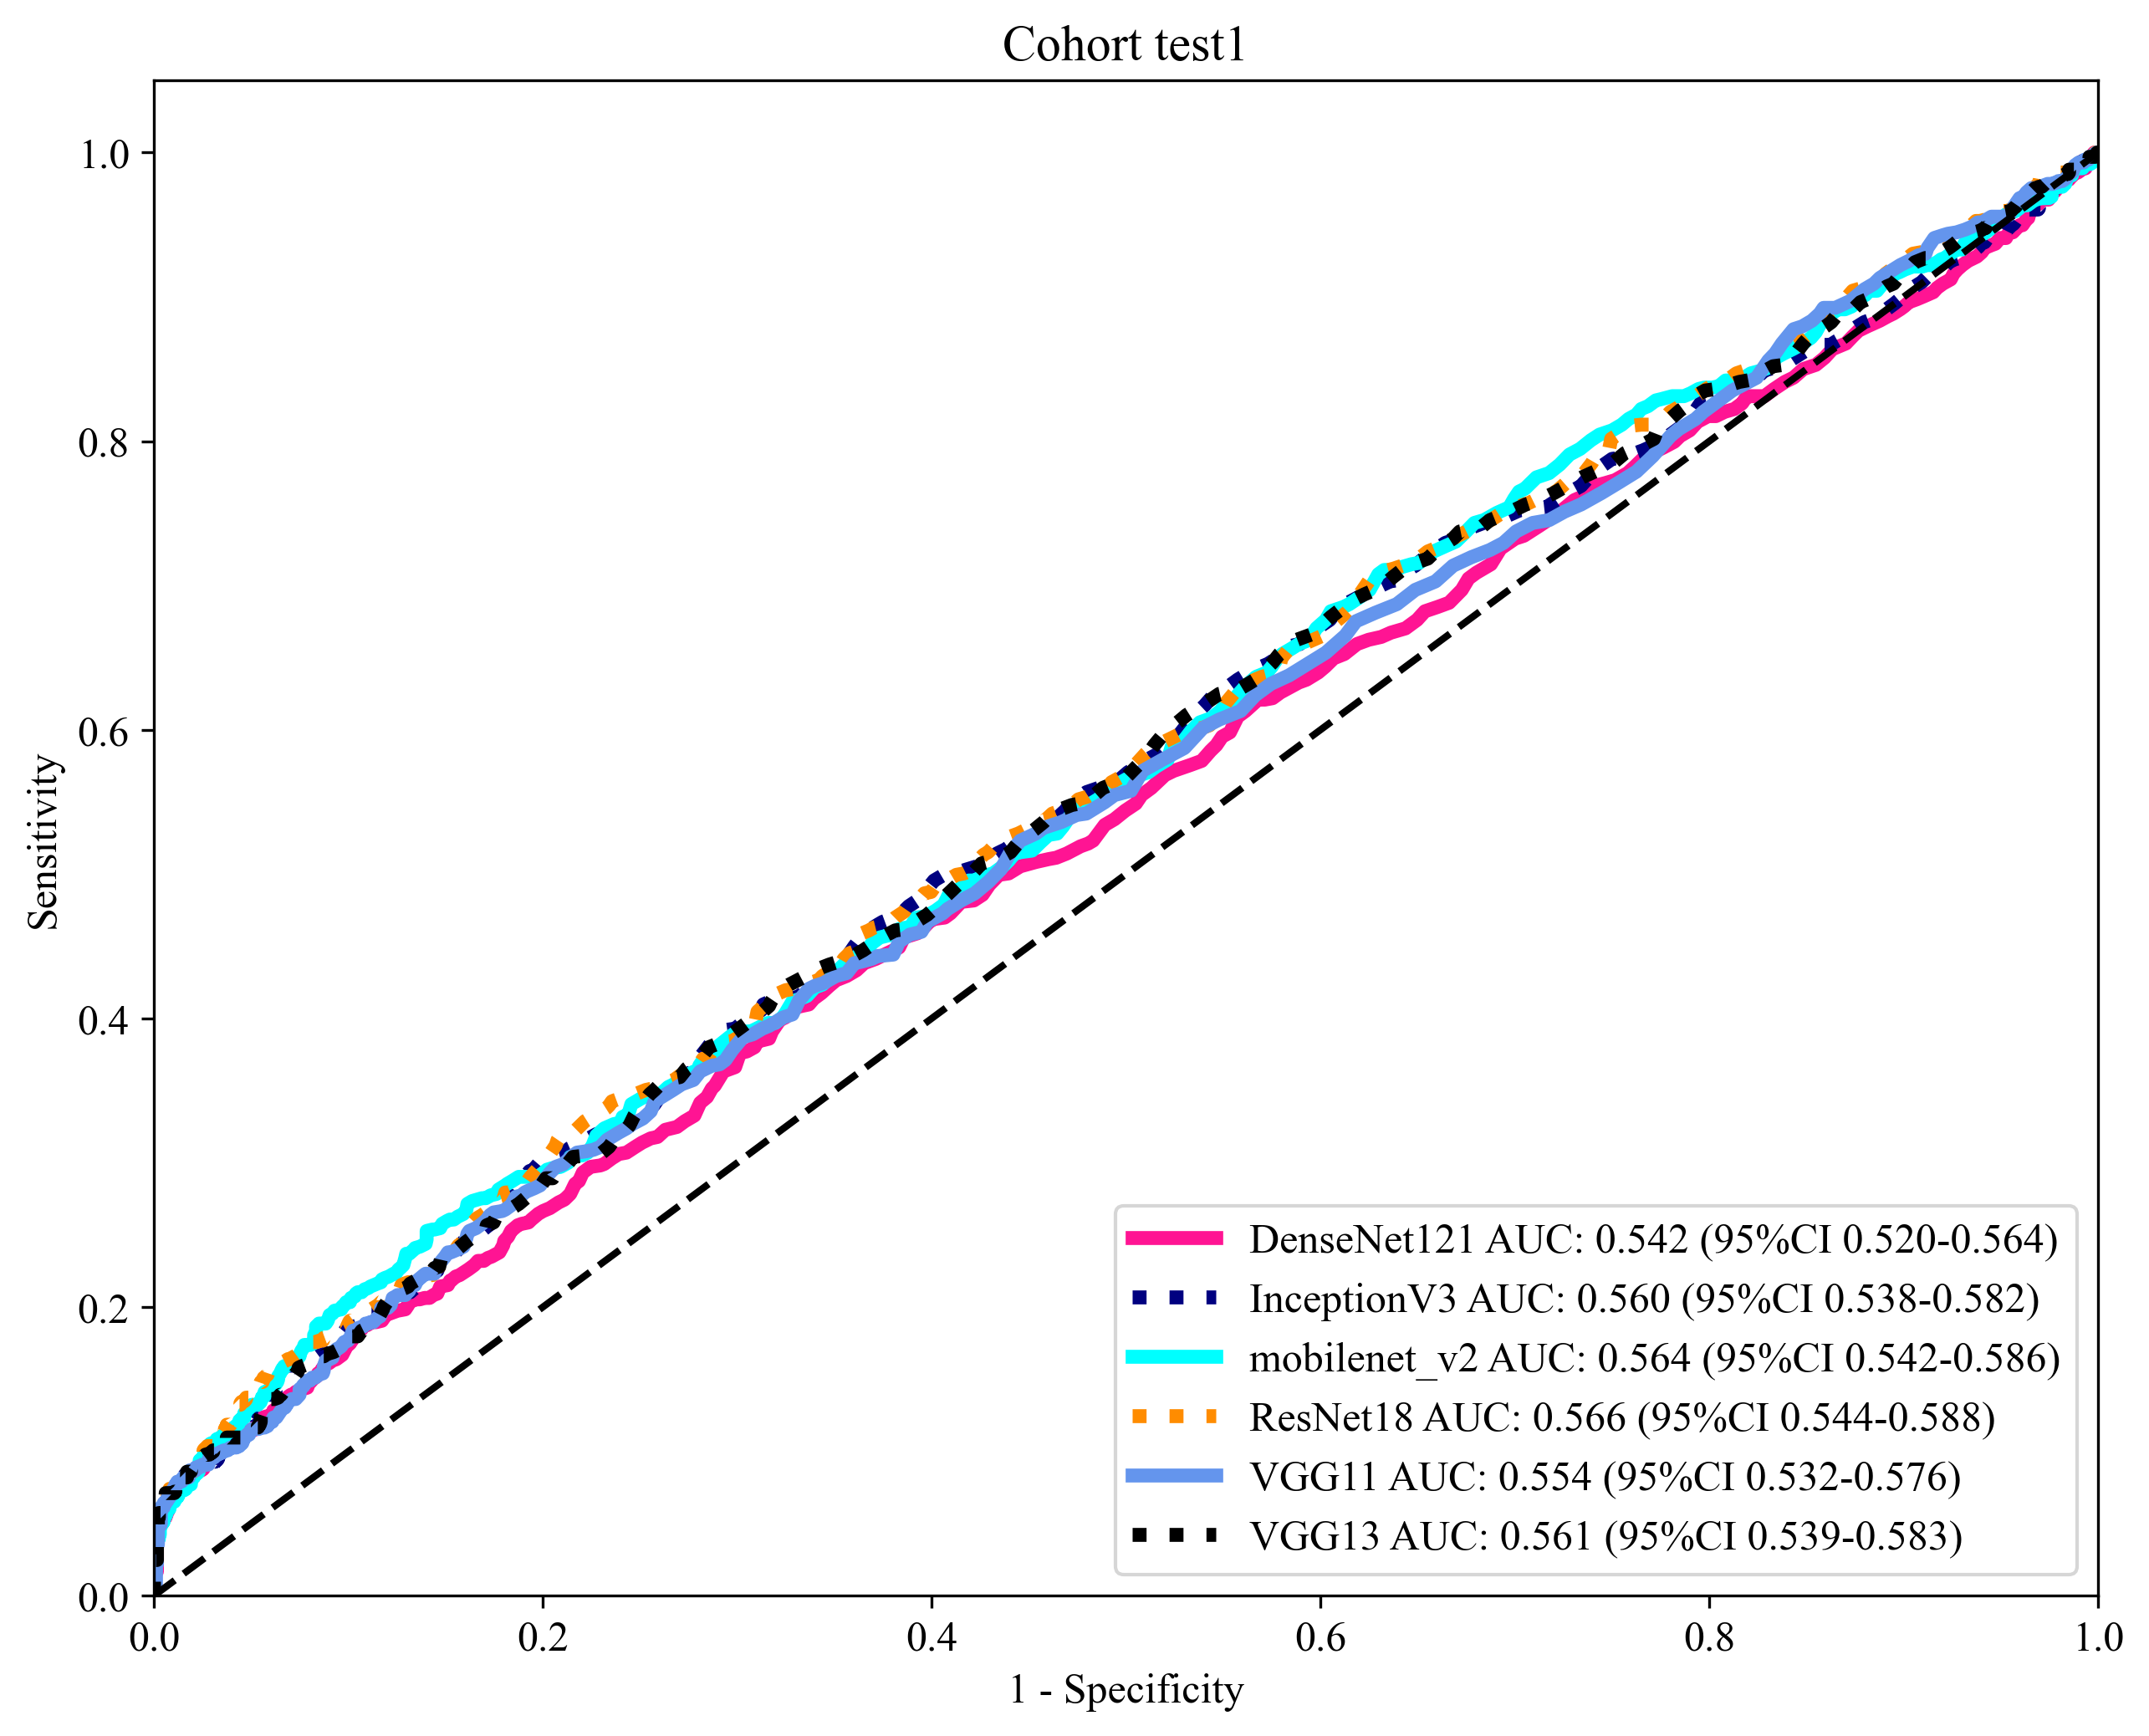

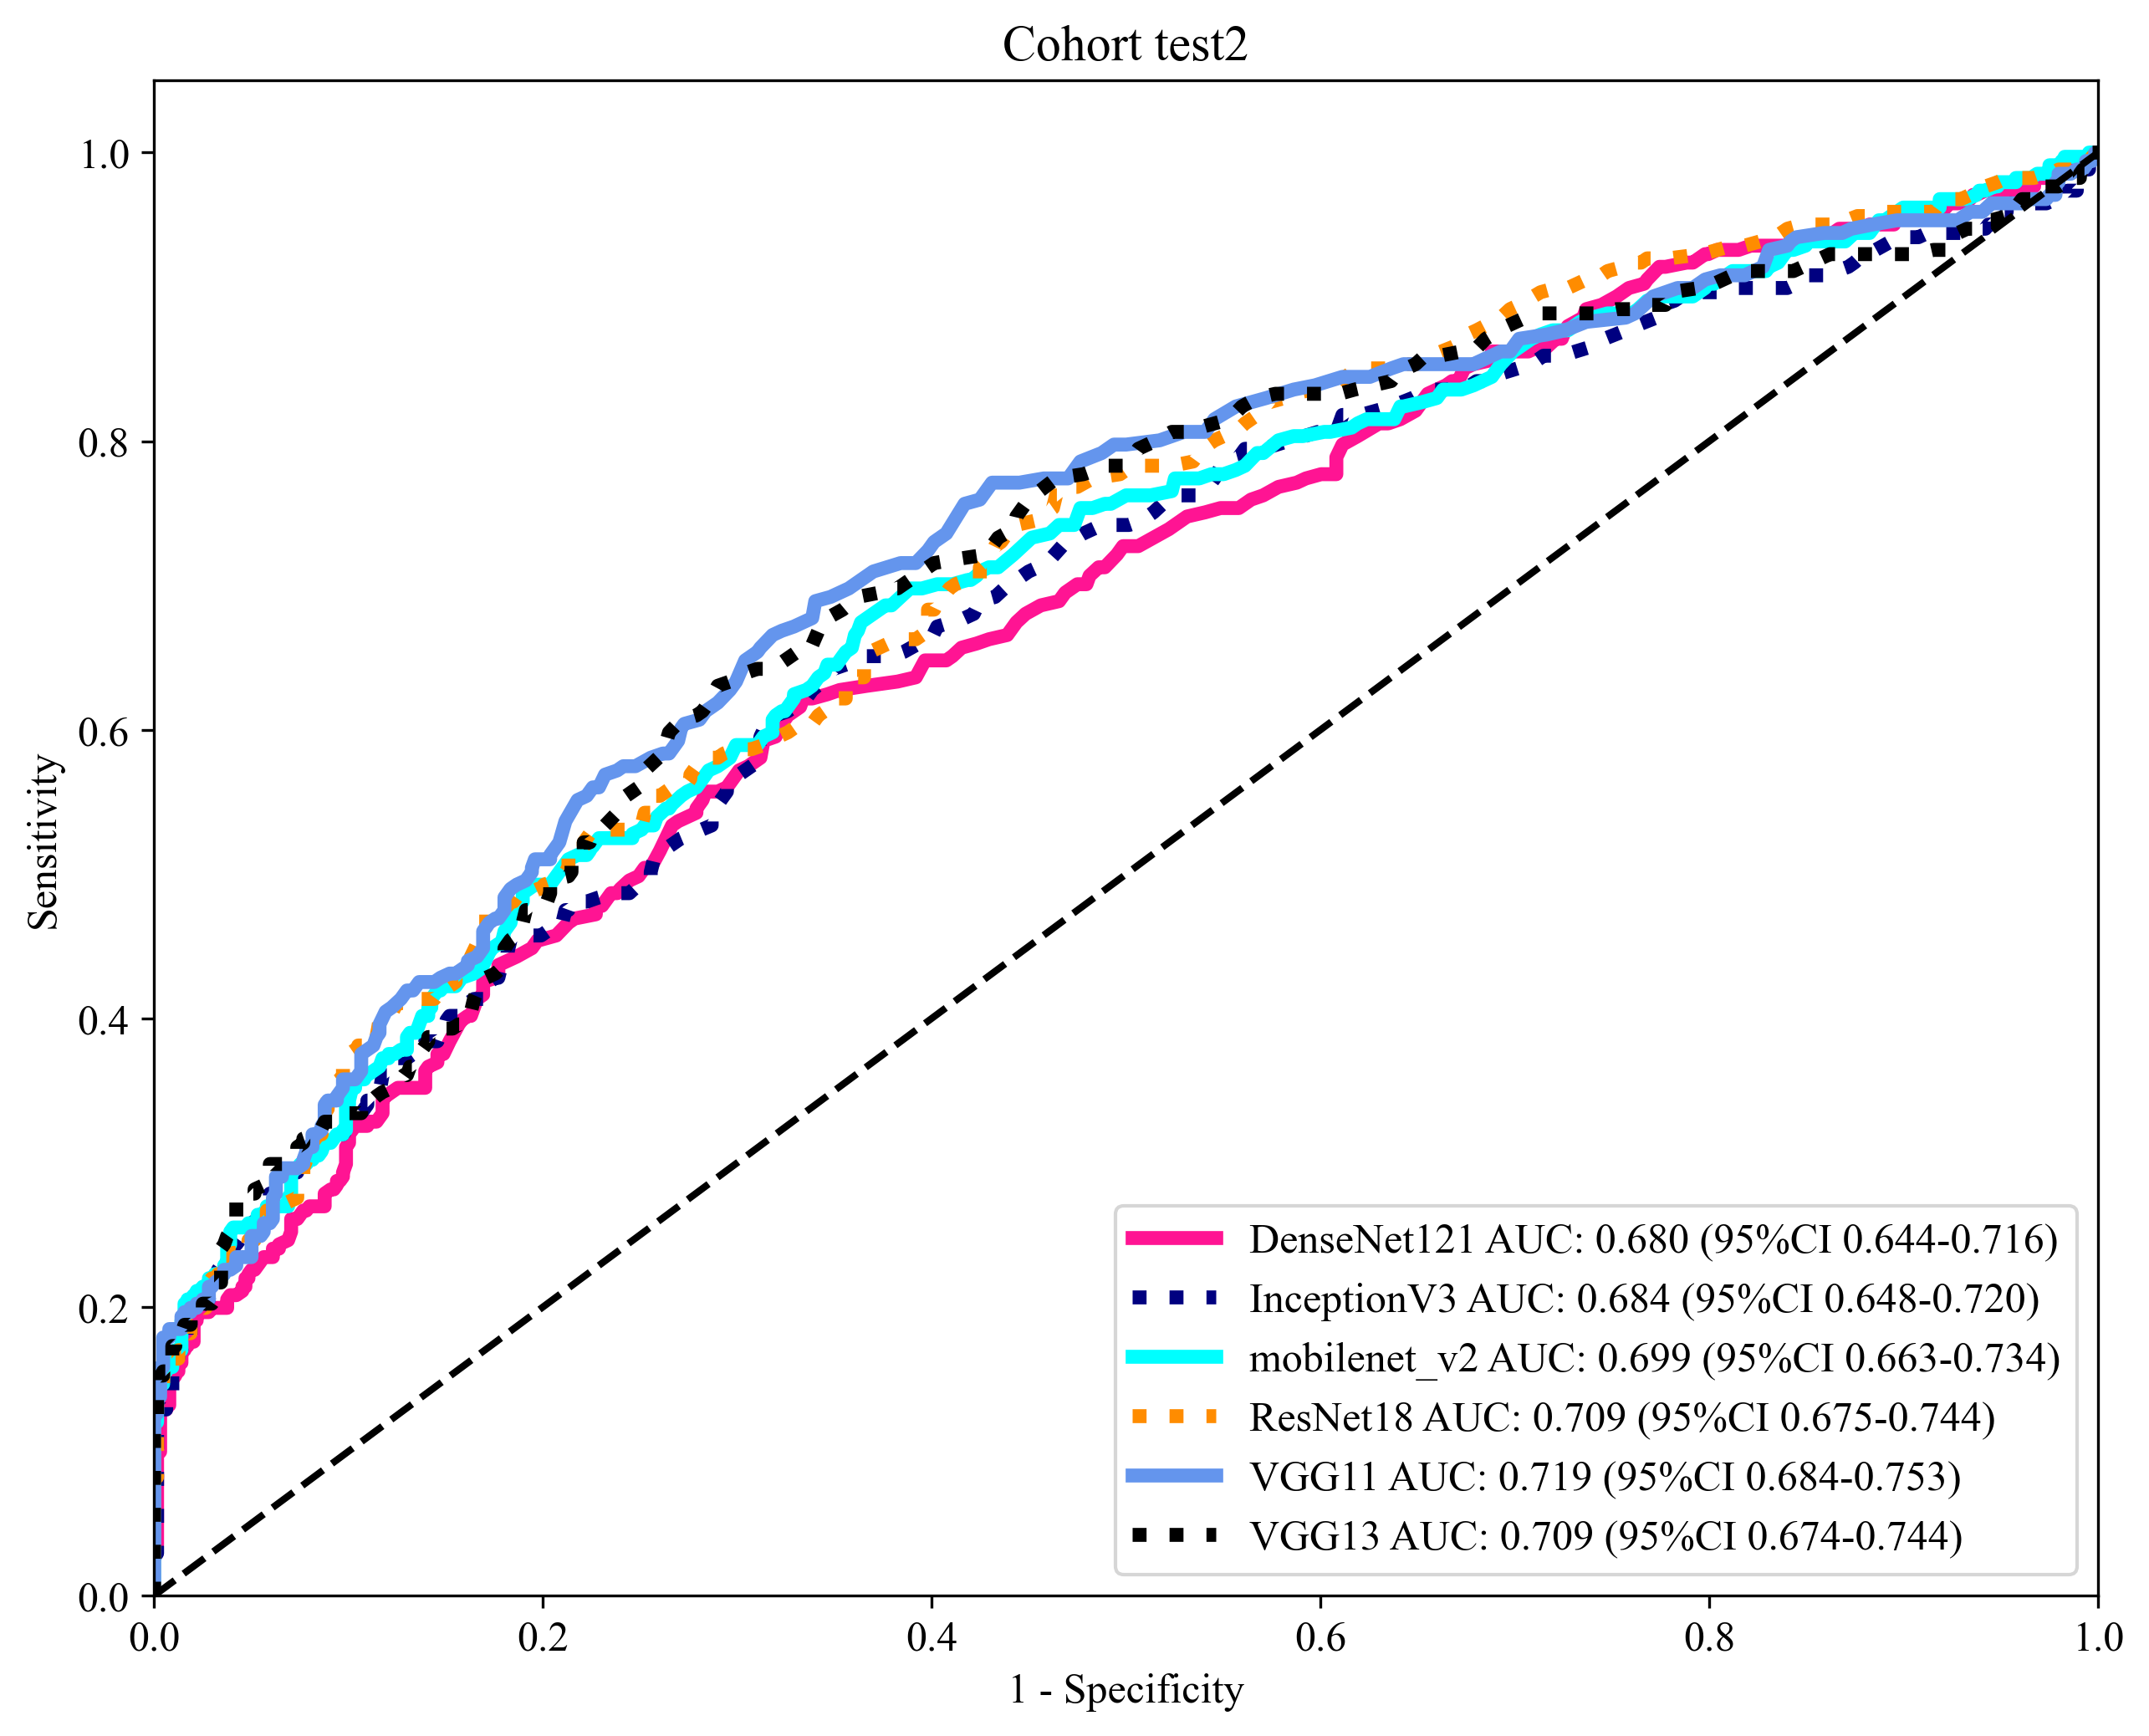

,ModelName,Acc,AUC,95% CI,Sensitivity,Specificity,PPV,NPV,Youden,Cohort
0,densenet121,0.706,0.574,0.5540-0.5943,0.284,0.839,0.358,0.787,0.305,train
1,densenet121,0.657,0.542,0.5197-0.5643,0.182,0.898,0.473,0.685,0.314,test1
2,densenet121,0.651,0.680,0.6444-0.7159,0.622,0.666,0.499,0.767,0.177,test2
3,inception_v3,0.561,0.636,0.6166-0.6547,0.668,0.528,0.309,0.834,0.172,train
4,inception_v3,0.633,0.560,0.5377-0.5822,0.299,0.802,0.433,0.694,0.253,test1
5,inception_v3,0.648,0.684,0.6478-0.7204,0.642,0.650,0.495,0.773,0.189,test2
6,mobilenet_v2,0.644,0.639,0.6195-0.6582,0.510,0.687,0.340,0.816,0.227,train
7,mobilenet_v2,0.656,0.564,0.5417-0.5860,0.253,0.860,0.477,0.695,0.320,test1
8,mobilenet_v2,0.650,0.699,0.6634-0.7343,0.674,0.636,0.498,0.785,0.216,test2
9,resnet18,0.622,0.616,0.5964-0.6350,0.525,0.652,0.323,0.813,0.222,train


,ModelName,Acc,AUC,95% CI,Sensitivity,Specificity,PPV,NPV,Youden,Cohort
0,densenet121,0.706,0.574,0.5540-0.5943,0.284,0.839,0.358,0.787,0.305,train
1,densenet121,0.657,0.542,0.5197-0.5643,0.182,0.898,0.473,0.685,0.314,test1
2,densenet121,0.651,0.680,0.6444-0.7159,0.622,0.666,0.499,0.767,0.177,test2
3,inception_v3,0.561,0.636,0.6166-0.6547,0.668,0.528,0.309,0.834,0.172,train
4,inception_v3,0.633,0.560,0.5377-0.5822,0.299,0.802,0.433,0.694,0.253,test1
5,inception_v3,0.648,0.684,0.6478-0.7204,0.642,0.650,0.495,0.773,0.189,test2
6,mobilenet_v2,0.644,0.639,0.6195-0.6582,0.510,0.687,0.340,0.816,0.227,train
7,mobilenet_v2,0.656,0.564,0.5417-0.5860,0.253,0.860,0.477,0.695,0.320,test1
8,mobilenet_v2,0.650,0.699,0.6634-0.7343,0.674,0.636,0.498,0.785,0.216,test2
9,resnet18,0.622,0.616,0.5964-0.6350,0.525,0.652,0.323,0.813,0.222,train


In [2]:
import pandas as pd
import numpy  as np
import re
from onekey_algo.custom.components import metrics
from onekey_algo.custom.components.comp1 import draw_roc, normalize_df
from onekey_algo.custom.components.ugly import drop_error
from matplotlib import pyplot as plt

def get_log(log_path, map2gz:bool = False):
    log_ = pd.read_csv(log_path, names=['fname', 'pred_score', 'pred_label', 'gt'], sep='\t')
    if map2gz:
        log_['ID'] = log_['fname'].map(lambda x: f"{os.path.basename(os.path.dirname(x))}.nii.gz")
    else:
        log_['ID'] = log_['fname'].map(lambda x: os.path.basename(os.path.dirname(x)))
    return log_

def map_mn(x):
    return x.replace('densen', 'DenseN').replace('resnet', 'ResNet').replace('vgg', 'VGG').replace('inception_v3', 'InceptionV3')

all_log_ = []
metrics_dfs = []
metric_results = []
all_preds = []
all_gts = []
all_model_names = []

model_root = os.path.join(get_param_in_cwd('model_root'))
for model in os.listdir(model_root):
    all_pred = []
    all_gt = []
    all_groups = []
    val_log = pd.concat([get_log(os.path.join(model_root, model, f"viz/BST_TRAIN_RESULTS.txt")),
                        get_log(os.path.join(model_root, model, f"viz/BST_VAL_RESULTS.txt"))], axis=0)
    val_log = pd.merge(val_log, group_info, on='ID', how='inner')
    val_log['model'] = f"{model}"
    ug_groups = get_param_in_cwd('subsets')
    ul_labels = np.unique(val_log['pred_label'])
    for g in ug_groups:
        sub_group = val_log[val_log['group'] == g]
        sub_group['label-1'] = list(map(lambda x: x[0] if x[1] == 1 else 1-x[0], 
                                        np.array(sub_group[['pred_score', 'pred_label']])))
        sub_group['label-0'] = 1 - sub_group['label-1']
        sub_group = normalize_df(sub_group, not_norm=[c for c in sub_group.columns if c != 'label-1'], method='minmax')
        all_groups.append(g)                    
        all_log_.append(sub_group)
        for ul in [1]:
            pred_score = np.array(sub_group['label-1']) 
            gt = [1 if gt_ == ul else 0 for gt_ in np.array(sub_group['gt'])]
            acc, auc, ci, tpr, tnr, ppv, npv, _, _, _, thres = metrics.analysis_pred_binary(gt, pred_score, use_youden=True)
            ci = f"{ci[0]:.4f}-{ci[1]:.4f}"
            metric_results.append([model, acc, auc, ci, tpr, tnr, ppv, npv, thres, g])
            all_pred.append(pred_score)
            all_gt.append(gt)
    # 绘制每个模型的ROC
    draw_roc(all_gt, all_pred, labels=all_groups, title=f'Model: {map_mn(model)}')
    plt.savefig(f'img/Patch_{model}_roc.svg', bbox_inches='tight')
    plt.show()
    # 整合到所有模型汇总。
    all_preds.extend(all_pred)
    all_gts.extend(all_gt)
    all_model_names.append(model)
for gi, g in enumerate(all_groups):
    draw_roc(all_gts[gi::len(all_groups)], all_preds[gi::len(all_groups)], 
             labels=[map_mn(m) for m in all_model_names], 
             title=f"Cohort {g}")
    plt.savefig(f'img/Patch_{g}_roc.svg', bbox_inches='tight')
    plt.show()
metrics_df = pd.DataFrame(metric_results, 
                          columns=['ModelName', 'Acc', 'AUC', '95% CI', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 
                                   'Youden', 'Cohort'])
display(metrics_df)
metrics_dfs.append(metrics_df)
pd.concat(metrics_dfs, axis=0)

# 保存预测结果

将深度学习的预测结果，保存中与组学的预测结果相同的格式，f1便后续进行汇总。

In [3]:
sel_model = get_param_in_cwd('sel_model', model)

all_logs = pd.concat(all_log_, axis=0)
sel_log = all_logs[all_logs['model'].str.contains(sel_model)]
sel_log[['ID', 'label-1', 'pred_label', 'gt']].to_csv('results/ALL_DL_PREDICTIONS.csv', index=False)
sel_log

,fname,pred_score,pred_label,gt,ID,group,model,label-1,label-0
0,E:\\qymnew\\JPG\181\181_000_000_000_000_000_04...,0.771,0,0,181,train,resnet18,0.203,0.771
1,E:\\qymnew\\JPG\181\181_000_000_000_000_000_05...,0.759,0,0,181,train,resnet18,0.215,0.759
2,E:\\qymnew\\JPG\181\181_000_000_000_000_000_00...,0.570,0,0,181,train,resnet18,0.412,0.570
3,E:\\qymnew\\JPG\181\181_000_000_000_000_000_04...,0.836,0,0,181,train,resnet18,0.135,0.836
4,E:\\qymnew\\JPG\181\181_000_000_000_000_000_05...,0.799,0,0,181,train,resnet18,0.174,0.799
...,...,...,...,...,...,...,...,...,...
8591,E:\\qymnew\\JPG\558\558_000_000_000_000_000_00...,0.676,0,0,558,test2,resnet18,0.290,0.676
8592,E:\\qymnew\\JPG\558\558_000_000_000_000_000_00...,0.814,0,0,558,test2,resnet18,0.143,0.814
8593,E:\\qymnew\\JPG\558\558_000_000_000_000_000_00...,0.733,0,0,558,test2,resnet18,0.229,0.733
8594,E:\\qymnew\\JPG\558\558_000_000_000_000_000_00...,0.768,0,0,558,test2,resnet18,0.192,0.768
